# Cyber-Physical Threat Detection: Inference Method Comparison

This notebook implements the full experimental comparison for the paper:
> *Quantum Bayesian Networks for Cyber-Physical Threat Prediction in Pipeline SCADA Systems*

**Bayesian Network:** HIL Water Distribution Testbed (Faramondi et al., *IEEE Access*, 2021)  
**Queries:** 4 diagnostically meaningful posteriors (defined in Phase 1 — Query Registry)  
**Methods compared (by phase):**
- Phase 1: Exact Inference (pgmpy VE), Classical Rejection Sampling (CRS), Quantum Rejection Sampling (QRS)
- Phase 2: Classical Likelihood Weighting (CLW)
- Phase 3: Quantum Likelihood Weighting (QLW)
- Phase 4: Classical Variational Inference (CVI), Quantum Variational Inference (QVI)
- Phase 5: Sensitivity Analysis
- Phase 6: Hardware (IBMQ)

Each stochastic method (CRS, QRS, ...) is run `N_RUNS = 10` times; results reported as mean ± std.

## Setup: Imports, BN Construction, Helpers

In [1]:
import logging
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')
logging.getLogger('qiskit').setLevel(logging.WARNING)
logging.getLogger('qiskit_aer').setLevel(logging.WARNING)

from qubayes.qubayes_tools import Node, Graph, QBNQuery
from qubayes.cyber_attack_bn import (
    ATTACK_ORDER,
    P_A1, A21,
    P_VALVE_S1, P_PUMP_S1, P_TANK_S1,
    P_VALVE_S2, P_FLOW_S2, P_TANK_S2,
)
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

# ── Experiment parameters ─────────────────────────────────────────────
MASTER_SEED  = 42
N_RUNS       = 10
CRS_SHOTS    = 1024
# 400
QRS_SHOTS    = 1024
# 512
QRS_ITERS    = 4      # Grover iterations (fixed; optimal-k analysis in Phase 1c)

rng   = np.random.default_rng(MASTER_SEED)
SEEDS = rng.integers(0, 9999, size=N_RUNS).tolist()
print(f"N_RUNS={N_RUNS}  |  Seeds: {SEEDS}")

# ── State mappings ────────────────────────────────────────────────────
ATTACK_STATES = {"Normal": 0, "MiTM": 1, "DoS": 2, "Physical": 3}
SENSOR_STATES = {"Normal": 0, "Abnormal": 1}

def str_to_idx(node_name, state_str):
    """Map a state string to its integer index for pgmpy."""
    if node_name in ("AttackType_1", "AttackType_2"):
        return ATTACK_STATES[state_str]
    return SENSOR_STATES[state_str]

# ── Emission CPT builder ──────────────────────────────────────────────
def make_emission_cpt_2x4(p_abnormal_by_attack_4, eps=1e-6):
    """
    Build a (2, 4) CPT for a binary sensor node.
    Row 0 = P(Normal|attack),  Row 1 = P(Abnormal|attack).
    Cols: [Normal, MiTM, DoS, Physical].
    """
    p_ab = np.clip(np.array(p_abnormal_by_attack_4, dtype=float), eps, 1.0 - eps)
    cpt  = np.zeros((2, 4), dtype=float)
    cpt[1, :] = p_ab
    cpt[0, :] = 1.0 - p_ab
    assert np.allclose(cpt.sum(axis=0), 1.0), "CPT columns must sum to 1."
    return cpt

# ── QBN construction (for QRS and CRS) ───────────────────────────────
attack1 = Node("AttackType_1", data=P_A1, states=ATTACK_STATES)
attack2 = Node("AttackType_2", parents=["AttackType_1"], data=A21, states=ATTACK_STATES)
valve1  = Node("ValveState_1", parents=["AttackType_1"], data=make_emission_cpt_2x4(P_VALVE_S1), states=SENSOR_STATES)
pump1   = Node("PumpState_1",  parents=["AttackType_1"], data=make_emission_cpt_2x4(P_PUMP_S1),  states=SENSOR_STATES)
tank1   = Node("TankState_1",  parents=["AttackType_1"], data=make_emission_cpt_2x4(P_TANK_S1),  states=SENSOR_STATES)
valve2  = Node("ValveState_2", parents=["AttackType_2"], data=make_emission_cpt_2x4(P_VALVE_S2), states=SENSOR_STATES)
flow2   = Node("FlowState_2",  parents=["AttackType_2"], data=make_emission_cpt_2x4(P_FLOW_S2),  states=SENSOR_STATES)
tank2   = Node("TankState_2",  parents=["AttackType_2"], data=make_emission_cpt_2x4(P_TANK_S2),  states=SENSOR_STATES)

graph = Graph({
    "AttackType_1": attack1, "AttackType_2": attack2,
    "ValveState_1": valve1,  "PumpState_1":  pump1,  "TankState_1": tank1,
    "ValveState_2": valve2,  "FlowState_2":  flow2,  "TankState_2": tank2,
})

qbn_query = QBNQuery()
qbn_query.graph_orig = graph
qbn_query.rebuild_qbn()
print("QBN ready. Nodes:", list(graph.nodes.keys()))

N_RUNS=10  |  Seeds: [892, 7738, 6545, 4388, 4329, 8585, 859, 6972, 2014, 941]
QBN ready. Nodes: ['AttackType_1', 'AttackType_2', 'ValveState_1', 'PumpState_1', 'TankState_1', 'ValveState_2', 'FlowState_2', 'TankState_2']


## Query Registry

Four queries selected to cover three types of causal reasoning over the BN:

| ID | Query | Reasoning Type |
|----|-------|----------------|
| Q1 | P(A2=Physical \| Flow2=Abn, Valve2=Abn) | Forward diagnosis — sensor evidence → S2 attack |
| Q2 | P(A1=Normal \| Flow2=Abn, Valve2=Abn)   | Upstream inference — sensor evidence → S1 cause |
| Q3 | P(A1=Normal \| A2=MiTM)                  | Attack propagation — S2 attack → S1 origin      |
| Q4 | P(A1=MiTM \| A2=MiTM)                    | Attack propagation — S2 attack → S1 origin      |

Q1 and Q2 share the same evidence (rare: P ≈ 0.3%) and test performance under rare-evidence conditions.  
Q3 and Q4 share the same evidence (common: P ≈ 1.2%) and form a complementary pair over A1 states given MiTM in A2.

In [2]:
QUERIES = [
    {
        "id"          : "Q1",
        "label"       : "P(A2=Physical | Flow2=Abn, Valve2=Abn)",
        "evidence"    : {"FlowState_2": "Abnormal", "ValveState_2": "Abnormal"},
        "target"      : {"AttackType_2": "Physical"},
        "target_var"  : "AttackType_2",
        "target_state": "Physical",
        "k"           : 8,   # deeper Grover amplification: 2-sensor S2 evidence, smaller p(evidence)
    },
    {
        "id"          : "Q2",
        "label"       : "P(A1=Normal | Flow2=Abn, Valve2=Abn)",
        "evidence"    : {"FlowState_2": "Abnormal", "ValveState_2": "Abnormal"},
        "target"      : {"AttackType_1": "Normal"},
        "target_var"  : "AttackType_1",
        "target_state": "Normal",
        "k"           : 8,   # deeper Grover amplification: upstream A1 query with 2-sensor S2 evidence
    },
    {
        "id"          : "Q3",
        "label"       : "P(A1=Normal | A2=MiTM)",
        "evidence"    : {"AttackType_2": "MiTM"},
        "target"      : {"AttackType_1": "Normal"},
        "target_var"  : "AttackType_1",
        "target_state": "Normal",
        "k"           : 4,   # shallower circuit: single discrete-state evidence, higher p(evidence)
    },
    {
        "id"          : "Q4",
        "label"       : "P(A1=MiTM | A2=MiTM)",
        "evidence"    : {"AttackType_2": "MiTM"},
        "target"      : {"AttackType_1": "MiTM"},
        "target_var"  : "AttackType_1",
        "target_state": "MiTM",
        "k"           : 4,   # shallower circuit: single discrete-state evidence, higher p(evidence)
    },
]
print(f"{len(QUERIES)} queries registered: {[q['id'] for q in QUERIES]}")

4 queries registered: ['Q1', 'Q2', 'Q3', 'Q4']


## Phase 1a — Exact Inference (pgmpy Variable Elimination)

Exact posterior via Variable Elimination serves as ground truth for all comparisons.  
The pgmpy model is constructed from the same CPT constants as the QBN.

In [3]:
# ── Build pgmpy DiscreteBayesianNetwork ───────────────────────────────
pgmpy_model = DiscreteBayesianNetwork([
    ("AttackType_1", "AttackType_2"),
    ("AttackType_1", "ValveState_1"),
    ("AttackType_1", "PumpState_1"),
    ("AttackType_1", "TankState_1"),
    ("AttackType_2", "ValveState_2"),
    ("AttackType_2", "FlowState_2"),
    ("AttackType_2", "TankState_2"),
])

def _sensor_cpd(name, parent, p_abnormal):
    cpt = make_emission_cpt_2x4(p_abnormal)
    return TabularCPD(name, 2, cpt.tolist(),
                      evidence=[parent], evidence_card=[4])

pgmpy_model.add_cpds(
    TabularCPD("AttackType_1", 4, [[v] for v in P_A1.tolist()]),
    TabularCPD("AttackType_2", 4, A21.tolist(),
               evidence=["AttackType_1"], evidence_card=[4]),
    _sensor_cpd("ValveState_1", "AttackType_1", P_VALVE_S1),
    _sensor_cpd("PumpState_1",  "AttackType_1", P_PUMP_S1),
    _sensor_cpd("TankState_1",  "AttackType_1", P_TANK_S1),
    _sensor_cpd("ValveState_2", "AttackType_2", P_VALVE_S2),
    _sensor_cpd("FlowState_2",  "AttackType_2", P_FLOW_S2),
    _sensor_cpd("TankState_2",  "AttackType_2", P_TANK_S2),
)

assert pgmpy_model.check_model(), "pgmpy model validation failed."
ve = VariableElimination(pgmpy_model)
print("pgmpy model ready. CPDs valid.")

pgmpy model ready. CPDs valid.


In [5]:
def exact_inference(q):
    """
    Run Variable Elimination for query q.
    Returns a single float: P(target_var=target_state | evidence).
    """
    evidence_int = {k: str_to_idx(k, v) for k, v in q["evidence"].items()}
    phi = ve.query([q["target_var"]], evidence=evidence_int, show_progress=False)
    idx = str_to_idx(q["target_var"], q["target_state"])
    return float(phi.values[idx])

print("Exact inference results:")
print("-" * 50)
exact_results = {}
for q in QUERIES:
    p = exact_inference(q)
    exact_results[q["id"]] = p
    print(f"  {q['id']}  {q['label']:<45}  {p:.6f}")

Exact inference results:
--------------------------------------------------
  Q1  P(A2=Physical | Flow2=Abn, Valve2=Abn)         0.665838
  Q2  P(A1=Normal | Flow2=Abn, Valve2=Abn)           0.696045
  Q3  P(A1=Normal | A2=MiTM)                         0.633183
  Q4  P(A1=MiTM | A2=MiTM)                           0.362633


## Phase 1b — Multi-Run CRS and QRS

Both methods are run `N_RUNS` times per query with different random seeds.  
Reported metrics:
- **mean ± std** of the posterior estimate across runs
- **acceptance rate** (fraction of shots consistent with evidence) — mean across runs
- **n_valid** — number of runs that returned at least one accepted sample (CRS can return NaN when evidence is very rare)

QRS uses **query-specific Grover iterations** (k): k=8 for Q1 and Q2 (2-sensor S2 evidence, smaller acceptance probability benefits from deeper amplification) and k=4 for Q3 and Q4 (single discrete-state evidence, higher acceptance probability). Optimal-k analysis across the full range follows in Phase 1c.

In [6]:
def run_crs(q, n_runs=N_RUNS, shots=CRS_SHOTS, seeds=SEEDS):
    """
    Run classical rejection sampling n_runs times for query q.
    Each run is seeded via np.random.seed() using the shared SEEDS list so
    that CRS results are reproducible across notebook runs — matching the
    reproducibility guarantee already in place for QRS.
    Returns dict of mean, std, acceptance rate, and n_valid.
    """
    qbn_query.evidence = dict(q["evidence"])
    qbn_query.target   = dict(q["target"])
    probs, accs = [], []
    for seed in seeds[:n_runs]:
        np.random.seed(int(seed))   # seed numpy global state before each draw
        prob, acc = qbn_query.perform_classical_rejection_sampling(shots=shots)
        probs.append(prob)
        accs.append(acc)
    probs = np.array(probs, dtype=float)
    accs  = np.array(accs,  dtype=float)
    return {
        "mean"   : float(np.nanmean(probs)),
        "std"    : float(np.nanstd(probs)),
        "acc"    : float(np.nanmean(accs)),
        "n_valid": int(np.sum(~np.isnan(probs))),
    }


def run_qrs(q, n_runs=N_RUNS, shots=QRS_SHOTS, iterations=QRS_ITERS, seeds=SEEDS):
    """
    Run quantum rejection sampling n_runs times for query q.
    Rebuilds the QBN circuit before each run (required after prior measurement).
    Returns dict of mean, std, acceptance rate, and n_valid.
    """
    qbn_query.evidence = dict(q["evidence"])
    qbn_query.target   = dict(q["target"])
    probs, accs = [], []
    for seed in seeds[:n_runs]:
        qbn_query.rebuild_qbn()
        prob, acc = qbn_query.perform_rejection_sampling(
            shots=shots, iterations=iterations,
            return_circuit_params=False, seed=int(seed), verbose=False
        )
        probs.append(prob)
        accs.append(acc)
    probs = np.array(probs, dtype=float)
    accs  = np.array(accs,  dtype=float)
    return {
        "mean"   : float(np.nanmean(probs)),
        "std"    : float(np.nanstd(probs)),
        "acc"    : float(np.nanmean(accs)),
        "n_valid": int(np.sum(~np.isnan(probs))),
    }

In [7]:
records = []

for q in QUERIES:
    print(f"\n{'='*60}")
    print(f"{q['id']}  {q['label']}")

    exact = exact_results[q["id"]]
    print(f"  Exact : {exact:.6f}")

    crs = run_crs(q)
    print(f"  CRS   : {crs['mean']:.4f} ± {crs['std']:.4f}  "
          f"acc={100*crs['acc']:.2f}%  valid={crs['n_valid']}/{N_RUNS}")

    qrs = run_qrs(q, iterations=q["k"])  # per-query Grover depth (Q1/Q2=8, Q3/Q4=4)
    print(f"  QRS   : {qrs['mean']:.4f} ± {qrs['std']:.4f}  "
          f"acc={100*qrs['acc']:.2f}%  valid={qrs['n_valid']}/{N_RUNS}")

    records.append({
        "id"         : q["id"],
        "label"      : q["label"],
        "exact"      : exact,
        "crs_mean"   : crs["mean"],
        "crs_std"    : crs["std"],
        "crs_acc"    : crs["acc"],
        "crs_n_valid": crs["n_valid"],
        "qrs_mean"   : qrs["mean"],
        "qrs_std"    : qrs["std"],
        "qrs_acc"    : qrs["acc"],
        "qrs_n_valid": qrs["n_valid"],
    })

print(f"\n{'='*60}")
print("All experiments complete.")


Q1  P(A2=Physical | Flow2=Abn, Valve2=Abn)
  Exact : 0.665838
  CRS   : 0.6588 ± 0.0853  acc=0.81%  valid=10/10
  QRS   : 0.6664 ± 0.0153  acc=99.67%  valid=10/10

Q2  P(A1=Normal | Flow2=Abn, Valve2=Abn)
  Exact : 0.696045
  CRS   : 0.6935 ± 0.1049  acc=0.81%  valid=10/10
  QRS   : 0.6959 ± 0.0168  acc=99.67%  valid=10/10

Q3  P(A1=Normal | A2=MiTM)
  Exact : 0.633183
  CRS   : 0.6224 ± 0.0514  acc=3.40%  valid=10/10
  QRS   : 0.6285 ± 0.0140  acc=99.75%  valid=10/10

Q4  P(A1=MiTM | A2=MiTM)
  Exact : 0.362633
  CRS   : 0.3653 ± 0.0512  acc=3.40%  valid=10/10
  QRS   : 0.3683 ± 0.0137  acc=99.75%  valid=10/10

All experiments complete.


## Phase 1 Results Table

The table below is the core result of Phase 1.  
**Error** = |method mean − exact|.  
**Acc%** = mean acceptance rate across runs (higher → more efficient sampling).  
**n_valid** = runs with at least one accepted sample (out of N_RUNS=10; CRS degrades for rare evidence).

In [8]:
df = pd.DataFrame(records)

display_df = pd.DataFrame({
    "Query"          : df["id"],
    "Exact"          : df["exact"].map("{:.4f}".format),
    "CRS (mean±std)" : df.apply(lambda r: f"{r.crs_mean:.4f} ± {r.crs_std:.4f}", axis=1),
    "CRS Err"        : (df["crs_mean"] - df["exact"]).abs().map("{:.4f}".format),
    "CRS Acc%"       : df["crs_acc"].map(lambda x: f"{100*x:.2f}%"),
    "CRS valid"      : df["crs_n_valid"].map(lambda x: f"{x}/{N_RUNS}"),
    "QRS (mean±std)" : df.apply(lambda r: f"{r.qrs_mean:.4f} ± {r.qrs_std:.4f}", axis=1),
    "QRS Err"        : (df["qrs_mean"] - df["exact"]).abs().map("{:.4f}".format),
    "QRS Acc%"       : df["qrs_acc"].map(lambda x: f"{100*x:.2f}%"),
    "QRS valid"      : df["qrs_n_valid"].map(lambda x: f"{x}/{N_RUNS}"),
})

pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 200)
print(display_df.to_string(index=False))

Query  Exact  CRS (mean±std) CRS Err CRS Acc% CRS valid  QRS (mean±std) QRS Err QRS Acc% QRS valid
   Q1 0.6658 0.6588 ± 0.0853  0.0071    0.81%     10/10 0.6664 ± 0.0153  0.0006   99.67%     10/10
   Q2 0.6960 0.6935 ± 0.1049  0.0025    0.81%     10/10 0.6959 ± 0.0168  0.0002   99.67%     10/10
   Q3 0.6332 0.6224 ± 0.0514  0.0108    3.40%     10/10 0.6285 ± 0.0140  0.0047   99.75%     10/10
   Q4 0.3626 0.3653 ± 0.0512  0.0027    3.40%     10/10 0.3683 ± 0.0137  0.0057   99.75%     10/10


In [9]:
# ── Acceptance rate speedup ───────────────────────────────────────────
# Key claim: QRS achieves dramatically higher acceptance rates than CRS
# for rare-evidence queries (Q1, Q2).

print("Acceptance rate comparison (QRS vs CRS speedup):")
print("-" * 50)
for row in records:
    crs_acc = row["crs_acc"]
    qrs_acc = row["qrs_acc"]
    speedup = qrs_acc / crs_acc if crs_acc > 0 else float('inf')
    print(f"  {row['id']}  CRS={100*crs_acc:.2f}%  QRS={100*qrs_acc:.2f}%  "
          f"speedup={speedup:.1f}x")

Acceptance rate comparison (QRS vs CRS speedup):
--------------------------------------------------
  Q1  CRS=0.81%  QRS=99.67%  speedup=123.0x
  Q2  CRS=0.81%  QRS=99.67%  speedup=123.0x
  Q3  CRS=3.40%  QRS=99.75%  speedup=29.4x
  Q4  CRS=3.40%  QRS=99.75%  speedup=29.4x


## Phase 1c — Optimal Grover Iterations Analysis

The standard Grover formula gives:
$$k_{\text{opt}} = \left\lfloor \frac{\pi}{4\theta} \right\rfloor, \quad \theta = \arcsin\!\left(\sqrt{P(\text{evidence})}\right)$$

Where $P(\text{evidence})$ is the prior probability of observing the evidence.

**Open question:** Is this formula correct for QBN rejection sampling, where the 'oracle' marks
states consistent with evidence in a joint-distribution-encoded quantum state?
This section:
1. Computes $P(\text{evidence})$ for each query from the joint BN distribution
2. Computes the formula-based $k_{\text{opt}}$
3. Sweeps $k \in \{1, 2, 3, 4, 5, 6, 8, 10\}$ and measures accuracy vs exact for each query
4. Compares empirically optimal $k$ to the formula prediction

This analysis will either validate the formula for QBN or motivate an alternative.
See: Brassard et al. (2002) *Quantum Amplitude Amplification and Estimation* for the theoretical basis.

In [10]:
def compute_p_evidence(q):
    """
    Compute P(evidence) = sum over all configs consistent with evidence
    using pgmpy joint probability.
    We query P(evidence) by marginalizing out all non-evidence variables.
    """
    evidence_int = {k: str_to_idx(k, v) for k, v in q["evidence"].items()}
    # Sum over all states of target variable to get P(evidence)
    phi = ve.query([q["target_var"]], evidence=evidence_int, show_progress=False)
    # phi.values sums to 1 (it's the posterior), so we need P(evidence) separately.
    # Use the joint probability approach: query all evidence nodes jointly.
    # pgmpy VariableElimination doesn't directly return P(evidence),
    # so we use the graph's sample_from_graph + empirical estimate as a check,
    # and compute it analytically via the joint CPT structure.
    #
    # Analytical: P(e) = sum_{all configs} P(all nodes) * 1[config matches evidence]
    joint_phi = ve.query(list(q["evidence"].keys()), evidence={}, show_progress=False)
    # Extract the marginal for the evidence configuration
    idx = tuple(str_to_idx(k, v) for k, v in q["evidence"].items())
    return float(joint_phi.values[idx])


def formula_optimal_k(p_evidence):
    """Standard Grover formula: k_opt = floor(pi / (4 * arcsin(sqrt(p))))."""
    if p_evidence <= 0:
        return float('inf')
    theta = np.arcsin(np.sqrt(p_evidence))
    return max(1, int(np.floor(np.pi / (4 * theta))))


print("P(evidence) and formula-based optimal k per query:")
print("-" * 55)
p_evidence_by_query = {}
for q in QUERIES:
    p_ev = compute_p_evidence(q)
    k_opt = formula_optimal_k(p_ev)
    p_evidence_by_query[q["id"]] = p_ev
    print(f"  {q['id']}  P(evidence)={p_ev:.6f}  theta={np.degrees(np.arcsin(np.sqrt(p_ev))):.2f}°  "
          f"k_opt(formula)={k_opt}")

P(evidence) and formula-based optimal k per query:
-------------------------------------------------------
  Q1  P(evidence)=0.009141  theta=5.49°  k_opt(formula)=8
  Q2  P(evidence)=0.009141  theta=5.49°  k_opt(formula)=8
  Q3  P(evidence)=0.031861  theta=10.28°  k_opt(formula)=4
  Q4  P(evidence)=0.031861  theta=10.28°  k_opt(formula)=4


In [11]:
# Sweep k values and record mean absolute error vs exact for each query
K_VALUES = [1, 2, 3, 4, 5, 6, 8, 10]
K_RUNS   = 5    # fewer runs for the sweep to keep runtime manageable
K_SEEDS  = SEEDS[:K_RUNS]

sweep_records = []
for q in QUERIES:
    exact = exact_results[q["id"]]
    for k in K_VALUES:
        res = run_qrs(q, n_runs=K_RUNS, iterations=k, seeds=K_SEEDS)
        mae = abs(res["mean"] - exact)
        sweep_records.append({
            "query": q["id"], "k": k,
            "mean" : res["mean"], "std": res["std"],
            "acc"  : res["acc"],  "mae": mae,
        })
        print(f"  {q['id']} k={k:2d}: mean={res['mean']:.4f}  mae={mae:.4f}  acc={100*res['acc']:.1f}%")

sweep_df = pd.DataFrame(sweep_records)
print("\nk-sweep complete.")

  Q1 k= 1: mean=0.6765  mae=0.0106  acc=8.6%
  Q1 k= 2: mean=0.6746  mae=0.0087  acc=22.6%
  Q1 k= 3: mean=0.6555  mae=0.0104  acc=40.1%
  Q1 k= 4: mean=0.6600  mae=0.0058  acc=59.7%
  Q1 k= 5: mean=0.6565  mae=0.0094  acc=76.7%
  Q1 k= 6: mean=0.6555  mae=0.0103  acc=90.2%
  Q1 k= 8: mean=0.6608  mae=0.0050  acc=99.7%
  Q1 k=10: mean=0.6548  mae=0.0110  acc=82.6%
  Q2 k= 1: mean=0.7050  mae=0.0089  acc=8.6%
  Q2 k= 2: mean=0.7044  mae=0.0083  acc=22.6%
  Q2 k= 3: mean=0.6858  mae=0.0102  acc=40.1%
  Q2 k= 4: mean=0.6927  mae=0.0033  acc=59.7%
  Q2 k= 5: mean=0.6821  mae=0.0139  acc=76.7%
  Q2 k= 6: mean=0.6852  mae=0.0108  acc=90.2%
  Q2 k= 8: mean=0.6884  mae=0.0076  acc=99.7%
  Q2 k=10: mean=0.6778  mae=0.0183  acc=82.6%
  Q3 k= 1: mean=0.6453  mae=0.0121  acc=27.3%
  Q3 k= 2: mean=0.6236  mae=0.0095  acc=63.1%
  Q3 k= 3: mean=0.6301  mae=0.0031  acc=90.8%
  Q3 k= 4: mean=0.6230  mae=0.0102  acc=99.8%
  Q3 k= 5: mean=0.6293  mae=0.0039  acc=85.2%
  Q3 k= 6: mean=0.6363  mae=0.0031  

In [12]:
# Pivot table: MAE at each k value per query
pivot = sweep_df.pivot(index='k', columns='query', values='mae')
pivot.columns.name = None
pivot.index.name   = 'k (Grover iters)'
print("MAE vs exact | lower is better")
print(pivot.round(4).to_string())

print("\nEmpirical best k per query:")
for qid in [q['id'] for q in QUERIES]:
    best_k = sweep_df[sweep_df['query'] == qid].sort_values('mae').iloc[0]
    formula_k = formula_optimal_k(p_evidence_by_query[qid])
    print(f"  {qid}  empirical best k={int(best_k['k'])}  formula k={formula_k}  "
          f"(formula {'matches' if int(best_k['k']) == formula_k else 'does NOT match'})")

MAE vs exact | lower is better
                      Q1      Q2      Q3      Q4
k (Grover iters)                                
1                 0.0106  0.0089  0.0121  0.0131
2                 0.0087  0.0083  0.0095  0.0100
3                 0.0104  0.0102  0.0031  0.0034
4                 0.0058  0.0033  0.0102  0.0106
5                 0.0094  0.0139  0.0039  0.0030
6                 0.0103  0.0108  0.0031  0.0036
8                 0.0050  0.0076  0.0292  0.0250
10                0.0110  0.0183  0.0104  0.0085

Empirical best k per query:
  Q1  empirical best k=8  formula k=8  (formula matches)
  Q2  empirical best k=4  formula k=8  (formula does NOT match)
  Q3  empirical best k=3  formula k=4  (formula does NOT match)
  Q4  empirical best k=5  formula k=4  (formula does NOT match)


## Phase 1 Summary

**Results are in `records` (list of dicts) and `df` (DataFrame).**  
**k-sweep results are in `sweep_df`.**

Phases 2–6 will add columns to `records` as each new method is implemented:
- Phase 2: `clw_mean`, `clw_std`, `clw_acc` (Classical Likelihood Weighting)
- Phase 3: `qlw_mean`, `qlw_std`, `qlw_acc` (Quantum Likelihood Weighting)
- Phase 4: `cvi_mean`, `cvi_std`, `qvi_mean`, `qvi_std` (Variational Inference)
- Phase 5: Sensitivity tables (separate cells)
- Phase 6: Hardware results (separate cells)

## Phase 2 — Classical Likelihood Weighting (CLW)

**Algorithm (Russell & Norvig, Ch. 14):**

1. Process nodes in topological order.
2. For each **non-evidence** node: sample from its CPT given already-sampled parents.
3. For each **evidence** node: fix its value to the observed state; multiply the running weight
   by P(evidence_val | sampled_parents). Do not sample.
4. Every sample contributes — nothing is thrown away.

The posterior estimate is:

$$\hat{P}(\text{target} \mid \text{evidence}) = \frac{\sum_i w_i \cdot \mathbf{1}[\text{sample}_i \text{ matches target}]}{\sum_i w_i}$$

**Why this is better than CRS for rare evidence:**
CRS uses ≈ P(evidence) × N samples effectively.
For Q1/Q2 where P(evidence) ≈ 0.2%, CRS uses ~1 out of 400 shots.
CLW uses all N samples with non-zero weights — no rejection.

**Effective Sample Size (ESS)** measures how many independent samples the weighted set is equivalent to:
$$\text{ESS} = \frac{(\sum_i w_i)^2}{\sum_i w_i^2}$$
ESS/N close to 1 means weights are uniform (ideal). ESS/N ≪ 1 means weight degeneracy
(a few samples dominate), which can happen when evidence is very rare.

**Note on existing code in `qubayes_tools.py`:**
`perform_qbn_likelihood_weighting` and `perform_likelihood_weighted_sampling` both filter samples
to evidence-matching ones first, then weight by P(evidence|parents). This double-counts the
evidence probability and gives no efficiency gain over rejection sampling.
The CLW implementation below is independent of those methods and correct.

In [15]:
# Pre-compute emission CPT arrays once (shape 2×4, row=sensor state, col=attack type)
CPT = {
    "AttackType_1" : P_A1,                          # shape (4,)
    "AttackType_2" : A21,                            # shape (4, 4)  col = A1 idx
    "ValveState_1" : make_emission_cpt_2x4(P_VALVE_S1),
    "PumpState_1"  : make_emission_cpt_2x4(P_PUMP_S1),
    "TankState_1"  : make_emission_cpt_2x4(P_TANK_S1),
    "ValveState_2" : make_emission_cpt_2x4(P_VALVE_S2),
    "FlowState_2"  : make_emission_cpt_2x4(P_FLOW_S2),
    "TankState_2"  : make_emission_cpt_2x4(P_TANK_S2),
}

# Parent map and topological order for the BN
PARENTS = {
    "AttackType_1": [],
    "AttackType_2": ["AttackType_1"],
    "ValveState_1": ["AttackType_1"],
    "PumpState_1" : ["AttackType_1"],
    "TankState_1" : ["AttackType_1"],
    "ValveState_2": ["AttackType_2"],
    "FlowState_2" : ["AttackType_2"],
    "TankState_2" : ["AttackType_2"],
}
TOPO_ORDER = [
    "AttackType_1", "AttackType_2",
    "ValveState_1", "PumpState_1", "TankState_1",
    "ValveState_2", "FlowState_2", "TankState_2",
]


def _one_clw_sample(evidence_int, rng):
    """
    Draw one weighted sample via classical likelihood weighting.
    Returns (sample dict, weight).
    """
    sample = {}
    w = 1.0
    for node in TOPO_ORDER:
        parents = PARENTS[node]
        cpt = CPT[node]

        # Get conditional probability vector for this node given sampled parents
        if len(parents) == 0:
            probs = cpt                         # shape (n_states,)
        elif len(parents) == 1:
            pa_idx = sample[parents[0]]
            probs = cpt[:, pa_idx]              # shape (n_states,)
        else:
            # Multi-parent (not needed for this BN, included for completeness)
            pa_idx = tuple(sample[p] for p in parents)
            probs = cpt[(...,) + pa_idx]

        probs = np.array(probs, dtype=float)
        probs = probs / probs.sum()             # normalise (guards numerical drift)

        if node in evidence_int:
            # Fix to evidence value — do not sample
            ev_val = evidence_int[node]
            sample[node] = ev_val
            w *= probs[ev_val]                  # accumulate likelihood weight
        else:
            sample[node] = int(rng.choice(len(probs), p=probs))

    return sample, w


def clw_estimate(q, n_samples, seed):
    """
    Classical likelihood weighting for query q.
    Returns (posterior estimate, ESS, ESS/n_samples).
    """
    evidence_int = {k: str_to_idx(k, v) for k, v in q["evidence"].items()}
    target_int   = {k: str_to_idx(k, v) for k, v in q["target"].items()}
    rng = np.random.default_rng(seed)

    weights         = np.zeros(n_samples)
    target_matches  = np.zeros(n_samples, dtype=bool)

    for i in range(n_samples):
        sample, w = _one_clw_sample(evidence_int, rng)
        weights[i]        = w
        target_matches[i] = all(sample[t] == v for t, v in target_int.items())

    w_sum     = weights.sum()
    w_sum_sq  = (weights ** 2).sum()
    ess       = (w_sum ** 2 / w_sum_sq) if w_sum_sq > 0 else 0.0
    posterior = float((weights * target_matches).sum() / w_sum) if w_sum > 0 else np.nan
    return posterior, ess, ess / n_samples


print("CLW implementation ready.")
print("Smoke test (Q1, 1 000 samples):")
p, ess, eff = clw_estimate(QUERIES[0], 1000, seed=42)
print(f"  P(A2=Physical | Flow2=Abn, Valve2=Abn) = {p:.4f}  "
      f"ESS={ess:.1f}  efficiency={100*eff:.1f}%")

CLW implementation ready.
Smoke test (Q1, 1 000 samples):
  P(A2=Physical | Flow2=Abn, Valve2=Abn) = 0.7170  ESS=21.5  efficiency=2.1%


In [16]:
CLW_SAMPLES = 1024   # match CRS shot count for a fair comparison

def run_clw(q, n_runs=N_RUNS, n_samples=CLW_SAMPLES, seeds=SEEDS):
    """Run CLW n_runs times; return mean, std, mean ESS, mean efficiency."""
    probs, ess_vals = [], []
    for seed in seeds[:n_runs]:
        p, ess, _ = clw_estimate(q, n_samples, seed=int(seed))
        probs.append(p)
        ess_vals.append(ess)
    probs    = np.array(probs,    dtype=float)
    ess_vals = np.array(ess_vals, dtype=float)
    return {
        "mean"       : float(np.nanmean(probs)),
        "std"        : float(np.nanstd(probs)),
        "ess_mean"   : float(np.nanmean(ess_vals)),
        "ess_eff"    : float(np.nanmean(ess_vals)) / n_samples,
        "n_valid"    : int(np.sum(~np.isnan(probs))),
    }


# Run CLW on all 4 queries and add results to records
print(f"Running CLW ({N_RUNS} runs × {CLW_SAMPLES} samples each)\n")
for rec in records:
    q = next(x for x in QUERIES if x["id"] == rec["id"])
    res = run_clw(q)
    rec["clw_mean"]    = res["mean"]
    rec["clw_std"]     = res["std"]
    rec["clw_ess"]     = res["ess_mean"]
    rec["clw_ess_eff"] = res["ess_eff"]
    rec["clw_n_valid"] = res["n_valid"]
    print(f"  {rec['id']}  {res['mean']:.4f} ± {res['std']:.4f}  "
          f"ESS={res['ess_mean']:.1f} ({100*res['ess_eff']:.1f}%)  "
          f"valid={res['n_valid']}/{N_RUNS}")

Running CLW (10 runs × 1024 samples each)

  Q1  0.6908 ± 0.0891  ESS=21.8 (2.1%)  valid=10/10
  Q2  0.7300 ± 0.0843  ESS=21.8 (2.1%)  valid=10/10
  Q3  0.6020 ± 0.0393  ESS=89.0 (8.7%)  valid=10/10
  Q4  0.3942 ± 0.0395  ESS=89.0 (8.7%)  valid=10/10


In [17]:
# ── Phase 2 Results: updated comparison table ─────────────────────────
df2 = pd.DataFrame(records)

display_df2 = pd.DataFrame({
    "Query"          : df2["id"],
    "Exact"          : df2["exact"].map("{:.4f}".format),
    "CRS (mean±std)" : df2.apply(lambda r: f"{r.crs_mean:.4f}±{r.crs_std:.4f}", axis=1),
    "CRS valid"      : df2["crs_n_valid"].map(lambda x: f"{x}/{N_RUNS}"),
    "CLW (mean±std)" : df2.apply(lambda r: f"{r.clw_mean:.4f}±{r.clw_std:.4f}", axis=1),
    "CLW ESS%"       : df2["clw_ess_eff"].map(lambda x: f"{100*x:.1f}%"),
    "QRS (mean±std)" : df2.apply(lambda r: f"{r.qrs_mean:.4f}±{r.qrs_std:.4f}", axis=1),
    "QRS Acc%"       : df2["qrs_acc"].map(lambda x: f"{100*x:.1f}%"),
})
pd.set_option('display.max_colwidth', None)
print(display_df2.to_string(index=False))

print("\nCLW vs CRS — std improvement (lower std = more consistent estimates):")
for _, row in df2.iterrows():
    improvement = row.crs_std / row.clw_std if row.clw_std > 0 else float('inf')
    print(f"  {row.id}  CRS std={row.crs_std:.4f}  CLW std={row.clw_std:.4f}  "
          f"{'CLW better' if improvement > 1 else 'CRS better'} ({improvement:.1f}x)")

Query  Exact CRS (mean±std) CRS valid CLW (mean±std) CLW ESS% QRS (mean±std) QRS Acc%
   Q1 0.6658  0.6588±0.0853     10/10  0.6908±0.0891     2.1%  0.6664±0.0153    99.7%
   Q2 0.6960  0.6935±0.1049     10/10  0.7300±0.0843     2.1%  0.6959±0.0168    99.7%
   Q3 0.6332  0.6224±0.0514     10/10  0.6020±0.0393     8.7%  0.6285±0.0140    99.7%
   Q4 0.3626  0.3653±0.0512     10/10  0.3942±0.0395     8.7%  0.3683±0.0137    99.7%

CLW vs CRS — std improvement (lower std = more consistent estimates):
  Q1  CRS std=0.0853  CLW std=0.0891  CRS better (1.0x)
  Q2  CRS std=0.1049  CLW std=0.0843  CLW better (1.2x)
  Q3  CRS std=0.0514  CLW std=0.0393  CLW better (1.3x)
  Q4  CRS std=0.0512  CLW std=0.0395  CLW better (1.3x)


## Phase 3 — Quantum Likelihood Weighting (QLW)

**Core idea:** Run the QBN circuit *without* Grover amplitude amplification to draw samples from the
joint prior distribution $P(\mathbf{X})$. Then **reweight** every measurement outcome by how
likely the evidence nodes would have taken their observed values, given the sampled parent states.

### Algorithm

1. **Sample from the prior** — run `perform_sampling(shots)` on the QBN circuit.  
   No Grover oracle. Every computational basis state is measured with probability proportional
   to $P(\mathbf{x})$.

2. **Decode each bitstring** — the binarized circuit encodes 4-state nodes across 2 qubits.  
   Sub-node `.0` (MSB) is assigned to the lower qubit index; sub-node `.1` (LSB) to the higher.  
   After reversing Qiskit's bit order, `state_idx = bits[q_low] * 2 + bits[q_high]`.

3. **Compute the likelihood weight** for each outcome:
$$w(\mathbf{x}) = \prod_{e \in \text{evidence}} P(E_e = e_{\text{obs}} \mid \text{parents}(E_e) = \mathbf{x}_{\text{parents}})$$
   No sample is discarded — samples where evidence nodes took a *different* value still contribute,
   but receive a lower weight proportional to $P(e_{\text{other}} \mid \text{parents})$.

4. **Posterior estimate:**
$$\hat{P}(\text{target} \mid \text{evidence}) =
\frac{\displaystyle\sum_{\mathbf{x}} \text{count}(\mathbf{x})\cdot w(\mathbf{x})\cdot\mathbf{1}[\mathbf{x}_{\text{target}} = t]}
     {\displaystyle\sum_{\mathbf{x}} \text{count}(\mathbf{x})\cdot w(\mathbf{x})}$$

### QLW vs CLW

| | CLW | QLW |
|---|---|---|
| Proposal | Classical ancestral sampler | QBN circuit (quantum sampler) |
| Evidence nodes | **Fixed** to observed value | **Free** — sampled by circuit |
| Weighting | $P(e_{\text{obs}} \mid \text{parents})$ | Same formula, applied post-measurement |
| ESS | Low for rare evidence (weight degeneracy) | Similar degeneracy but with quantum speedup potential |

The key difference is the *source* of samples: the QBN circuit exploits quantum superposition to
sample all states simultaneously, making the proposal distribution identical to the classical one
on a noiseless simulator. On real quantum hardware, decoherence introduces a bias that this
comparison will reveal in Phase 6.

**ESS** is computed accounting for repeated bitstrings (grouped shots):
$$\text{ESS} = \frac{\left(\sum_i c_i \cdot w_i\right)^2}{\sum_i c_i \cdot w_i^2}$$
where $c_i$ is the shot count and $w_i$ the likelihood weight for unique bitstring $i$.

In [18]:
import io
import contextlib

# ─────────────────────────────────────────────────────────────────────────────
# Bitstring decoder
# ─────────────────────────────────────────────────────────────────────────────
# After rebuild_qbn(), the binarized QBN circuit has the following qubit layout
# (for our 8-node BN with no ancillas, 10 qubits total):
#
#   qubit 0  = AttackType_1.0  (MSB of AttackType_1)
#   qubit 1  = AttackType_1.1  (LSB of AttackType_1)
#   qubit 2  = AttackType_2.0  (MSB of AttackType_2)
#   qubit 3  = AttackType_2.1  (LSB of AttackType_2)
#   qubit 4  = ValveState_1
#   qubit 5  = PumpState_1
#   qubit 6  = TankState_1
#   qubit 7  = ValveState_2
#   qubit 8  = FlowState_2
#   qubit 9  = TankState_2
#
# Qiskit returns bitstrings in reverse qubit order (qubit 9 leftmost).
# After bits = list(map(int, bitstring[::-1])), bits[i] = value of qubit i.
#
# For 4-state nodes: state_idx = .0_val * 2 + .1_val
#   i.e. sorted_qubits = [q_for_.0, q_for_.1], bit_str = bits[q_low]+bits[q_high]
#   int(bit_str, 2) = MSB*2 + LSB = state_idx  ✓

def _build_var_qubit_map():
    """
    Build {var_name: sorted_list_of_qubit_indices} from the current qbn_query.qbn.
    Must be called after rebuild_qbn().
    For binary nodes, list has length 1.
    For 4-state nodes, list = [qubit_for_.0 (MSB), qubit_for_.1 (LSB)] sorted ascending.
    """
    var_map = {}
    for var in TOPO_ORDER:
        qubits = sorted(qbn_query.qbn.get_qubits_from_attribute(var))
        var_map[var] = qubits
    return var_map


def _decode_bitstring(bitstring, var_qubit_map):
    """
    Decode a Qiskit measurement bitstring to {var_name: state_int}.

    Qiskit convention: leftmost char = highest qubit index.
    After reversal: bits[i] = value measured at qubit i.

    Binary node  (1 qubit):  state_idx = bits[qubit]
    4-state node (2 qubits): state_idx = bits[q_low]*2 + bits[q_high]
                              = int(str(bits[q_low])+str(bits[q_high]), 2)
    """
    bits = list(map(int, bitstring[::-1]))  # bits[qubit_idx] = measured bit
    sample = {}
    for var, qubits in var_qubit_map.items():
        if len(qubits) == 1:
            sample[var] = bits[qubits[0]]
        else:
            # qubits is already sorted ascending: [q_for_.0(MSB), q_for_.1(LSB)]
            bit_str = ''.join(str(bits[q]) for q in qubits)
            sample[var] = int(bit_str, 2)
    return sample


# ─────────────────────────────────────────────────────────────────────────────
# QLW estimator
# ─────────────────────────────────────────────────────────────────────────────

def qlw_estimate(q, shots, seed):
    """
    Quantum Likelihood Weighting for query q.

    Steps:
      1. Rebuild and run QBN circuit (no Grover) — samples from prior P(X).
      2. Decode each bitstring to classical variable assignments.
      3. Compute per-bitstring weight = Π P(e_obs | sampled_parents(e)).
         All bitstrings contribute; no filtering.
      4. Posterior = Σ(count*w * 1[target_match]) / Σ(count*w).
      5. ESS = (Σ count*w)² / Σ(count*w²)   [grouped-shot formula].

    Returns (posterior, ESS, ESS/shots).
    """
    qbn_query.rebuild_qbn()
    var_qubit_map = _build_var_qubit_map()

    evidence_int = {k: str_to_idx(k, v) for k, v in q["evidence"].items()}
    target_int   = {k: str_to_idx(k, v) for k, v in q["target"].items()}

    # Run circuit — suppress the print() inside perform_sampling
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        result = qbn_query.qbn.perform_sampling(shots=shots, seed=seed)

    total_w      = 0.0
    target_w     = 0.0
    ess_denom    = 0.0   # Σ count*w²  (for grouped-shot ESS)

    for bitstring, count in result.items():
        sample = _decode_bitstring(bitstring, var_qubit_map)

        # Likelihood weight: Π P(e_obs | sampled_parents(e))
        w = 1.0
        for ev_var, ev_val in evidence_int.items():
            parents = PARENTS[ev_var]
            cpt     = CPT[ev_var]
            if len(parents) == 0:
                probs = np.array(cpt, dtype=float)
            elif len(parents) == 1:
                probs = np.array(cpt[:, sample[parents[0]]], dtype=float)
            else:
                pa_idx = tuple(sample[p] for p in parents)
                probs  = np.array(cpt[(...,) + pa_idx], dtype=float)
            probs /= probs.sum()   # guard numerical drift
            w     *= probs[ev_val]

        weighted_count = count * w
        total_w     += weighted_count
        ess_denom   += count * (w ** 2)   # Σ count*w²

        target_match = all(sample[t] == v for t, v in target_int.items())
        if target_match:
            target_w += weighted_count

    if total_w == 0:
        return np.nan, 0.0, 0.0

    posterior = float(target_w / total_w)
    ess       = float((total_w ** 2) / ess_denom) if ess_denom > 0 else 0.0
    return posterior, ess, ess / shots


def run_qlw(q, n_runs=N_RUNS, shots=QRS_SHOTS, seeds=SEEDS):
    """Run QLW n_runs times; return mean, std, mean ESS, mean ESS efficiency."""
    probs, ess_vals = [], []
    for seed in seeds[:n_runs]:
        p, ess, _ = qlw_estimate(q, shots=shots, seed=int(seed))
        probs.append(p)
        ess_vals.append(ess)
    probs    = np.array(probs,    dtype=float)
    ess_vals = np.array(ess_vals, dtype=float)
    return {
        "mean"    : float(np.nanmean(probs)),
        "std"     : float(np.nanstd(probs)),
        "ess_mean": float(np.nanmean(ess_vals)),
        "ess_eff" : float(np.nanmean(ess_vals)) / shots,
        "n_valid" : int(np.sum(~np.isnan(probs))),
    }


# ── Smoke test ────────────────────────────────────────────────────────
print("QLW implementation ready.")
print(f"Shots per run: {QRS_SHOTS}  (same as QRS for fair comparison)\n")
print("Smoke test (Q3 — P(A1=Normal | A2=MiTM), 1 run, seed=42):")
p_smoke, ess_smoke, eff_smoke = qlw_estimate(QUERIES[2], shots=QRS_SHOTS, seed=42)
print(f"  posterior = {p_smoke:.4f}  (exact = {exact_results['Q3']:.4f})")
print(f"  ESS = {ess_smoke:.1f}  efficiency = {100*eff_smoke:.1f}%")

QLW implementation ready.
Shots per run: 1024  (same as QRS for fair comparison)

Smoke test (Q3 — P(A1=Normal | A2=MiTM), 1 run, seed=42):
  posterior = 0.7312  (exact = 0.6332)
  ESS = 107.0  efficiency = 10.4%


In [19]:
# ── Run QLW for all 4 queries ─────────────────────────────────────────
print(f"Running QLW ({N_RUNS} runs × {QRS_SHOTS} shots each)\n")
print(f"{'='*65}")

for rec in records:
    q   = next(x for x in QUERIES if x["id"] == rec["id"])
    res = run_qlw(q)
    rec["qlw_mean"]    = res["mean"]
    rec["qlw_std"]     = res["std"]
    rec["qlw_ess"]     = res["ess_mean"]
    rec["qlw_ess_eff"] = res["ess_eff"]
    rec["qlw_n_valid"] = res["n_valid"]

    err = abs(res["mean"] - exact_results[rec["id"]])
    print(f"  {rec['id']}  {res['mean']:.4f} ± {res['std']:.4f}  "
          f"err={err:.4f}  ESS={res['ess_mean']:.1f} ({100*res['ess_eff']:.1f}%)  "
          f"valid={res['n_valid']}/{N_RUNS}")

print(f"\n{'='*65}")
print("QLW complete.")

Running QLW (10 runs × 1024 shots each)

  Q1  0.6757 ± 0.1016  err=0.0099  ESS=23.0 (2.2%)  valid=10/10
  Q2  0.7023 ± 0.0989  err=0.0063  ESS=23.0 (2.2%)  valid=10/10
  Q3  0.6543 ± 0.0655  err=0.0211  ESS=94.9 (9.3%)  valid=10/10
  Q4  0.3412 ± 0.0658  err=0.0214  ESS=94.9 (9.3%)  valid=10/10

QLW complete.


In [20]:
# ── Phase 3 Results: full comparison table ───────────────────────────
df3 = pd.DataFrame(records)

display_df3 = pd.DataFrame({
    "Query"          : df3["id"],
    "Exact"          : df3["exact"].map("{:.4f}".format),
    "CRS (mean±std)" : df3.apply(lambda r: f"{r.crs_mean:.4f}±{r.crs_std:.4f}", axis=1),
    "CRS Acc%"       : df3["crs_acc"].map(lambda x: f"{100*x:.1f}%"),
    "CLW (mean±std)" : df3.apply(lambda r: f"{r.clw_mean:.4f}±{r.clw_std:.4f}", axis=1),
    "CLW ESS%"       : df3["clw_ess_eff"].map(lambda x: f"{100*x:.1f}%"),
    "QRS (mean±std)" : df3.apply(lambda r: f"{r.qrs_mean:.4f}±{r.qrs_std:.4f}", axis=1),
    "QRS Acc%"       : df3["qrs_acc"].map(lambda x: f"{100*x:.1f}%"),
    "QLW (mean±std)" : df3.apply(lambda r: f"{r.qlw_mean:.4f}±{r.qlw_std:.4f}", axis=1),
    "QLW ESS%"       : df3["qlw_ess_eff"].map(lambda x: f"{100*x:.1f}%"),
})

pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 220)
print("Full comparison table (Phases 1–3):")
print(display_df3.to_string(index=False))

# ── ESS comparison: CLW vs QLW ────────────────────────────────────────
print("\nESS comparison (CLW vs QLW) — higher ESS% = less weight degeneracy:")
print("-" * 60)
for _, row in df3.iterrows():
    clw_eff = 100 * row.clw_ess_eff
    qlw_eff = 100 * row.qlw_ess_eff
    better  = "QLW" if qlw_eff > clw_eff else "CLW"
    ratio   = max(qlw_eff, clw_eff) / min(qlw_eff, clw_eff) if min(qlw_eff, clw_eff) > 0 else float('inf')
    print(f"  {row.id}  CLW ESS%={clw_eff:.1f}%  QLW ESS%={qlw_eff:.1f}%  → {better} better ({ratio:.1f}x)")

print("\nError vs exact (|mean - exact|):")
print("-" * 60)
for _, row in df3.iterrows():
    print(f"  {row.id}  "
          f"CRS={abs(row.crs_mean - row.exact):.4f}  "
          f"CLW={abs(row.clw_mean - row.exact):.4f}  "
          f"QRS={abs(row.qrs_mean - row.exact):.4f}  "
          f"QLW={abs(row.qlw_mean - row.exact):.4f}")

Full comparison table (Phases 1–3):
Query  Exact CRS (mean±std) CRS Acc% CLW (mean±std) CLW ESS% QRS (mean±std) QRS Acc% QLW (mean±std) QLW ESS%
   Q1 0.6658  0.6588±0.0853     0.8%  0.6908±0.0891     2.1%  0.6664±0.0153    99.7%  0.6757±0.1016     2.2%
   Q2 0.6960  0.6935±0.1049     0.8%  0.7300±0.0843     2.1%  0.6959±0.0168    99.7%  0.7023±0.0989     2.2%
   Q3 0.6332  0.6224±0.0514     3.4%  0.6020±0.0393     8.7%  0.6285±0.0140    99.7%  0.6543±0.0655     9.3%
   Q4 0.3626  0.3653±0.0512     3.4%  0.3942±0.0395     8.7%  0.3683±0.0137    99.7%  0.3412±0.0658     9.3%

ESS comparison (CLW vs QLW) — higher ESS% = less weight degeneracy:
------------------------------------------------------------
  Q1  CLW ESS%=2.1%  QLW ESS%=2.2%  → QLW better (1.1x)
  Q2  CLW ESS%=2.1%  QLW ESS%=2.2%  → QLW better (1.1x)
  Q3  CLW ESS%=8.7%  QLW ESS%=9.3%  → QLW better (1.1x)
  Q4  CLW ESS%=8.7%  QLW ESS%=9.3%  → QLW better (1.1x)

Error vs exact (|mean - exact|):
-------------------------------

---
## Phase 4 — Variational Inference

Variational inference replaces sampling with **optimisation**: find a distribution
$Q(\mathbf{z})$ in a chosen family that is as close as possible to the true posterior
$P(\mathbf{z} \mid \mathbf{e})$ by minimising the KL divergence (equivalently, maximising
the ELBO).

Unlike rejection sampling and likelihood weighting, VI:
- Introduces a **systematic bias** determined by the expressiveness of the $Q$ family
- Is **deterministic** once initialised — no shot noise after convergence
- Is **unaffected by evidence rarity** — rare and common evidence queries are equally tractable

### Methods compared

| Method | Q family | Optimiser |
|--------|----------|-----------|
| **CAVI** | Mean-field: $Q(A_1)\,Q(A_2)$ | Coordinate ascent (closed-form updates) |
| **QVI-RA0** | Born machine — RealAmplitudes reps=0 (product state) | COBYLA |
| **QVI-RA1** | Born machine — RealAmplitudes reps=1 (entangled) | COBYLA |
| **QVI-BN** | Born machine — BN-structured ansatz (problem-inspired) | COBYLA |

### Query grouping
Q1 and Q2 share evidence → run once, read $Q(A_2)$ for Q1 and $Q(A_1)$ for Q2.  
Q3 and Q4 share evidence → run once, read $Q(A_1{=}\text{Normal})$ for Q3 and
$Q(A_1{=}\text{MiTM})$ for Q4.

### Phase 4a — Classical Variational Inference (CAVI)

**Mean-field assumption:** $Q(A_1, A_2) = Q(A_1)\,Q(A_2)$, each a categorical distribution
over 4 attack states.

**Coordinate Ascent VI (CAVI) updates** (iterate until convergence):

$$\log Q(A_2 = j) \;\propto\; \sum_i Q(A_1{=}i)\,\log P(A_2{=}j \mid A_1{=}i)
  \;+\; \log P(\mathbf{e}_{\text{sensor}} \mid A_2{=}j)$$

$$\log Q(A_1 = i) \;\propto\; \log P(A_1{=}i)
  \;+\; \sum_j Q(A_2{=}j)\,\log P(A_2{=}j \mid A_1{=}i)$$

When evidence is a direct observation of $A_2$ (Q3/Q4), there is no free $Q(A_2)$ —
the update for $Q(A_1)$ closes in a single step and recovers the exact posterior.

**ELBO** (tracked for convergence):
$$\text{ELBO} = \mathbb{E}_Q[\log P(A_1)] + \mathbb{E}_Q[\log P(A_2 \mid A_1)]
+ \mathbb{E}_Q[\log P(\mathbf{e} \mid A_2)] + H[Q(A_1)] + H[Q(A_2)]$$

In [21]:

from qubayes.cyber_attack_bn import (
    CyberAttackA2BN, CyberAttackA1BN,
    P_A1, A21,
    P_VALVE_S1, P_PUMP_S1, P_TANK_S1,
    P_VALVE_S2, P_FLOW_S2, P_TANK_S2,
)

_SENSOR_PROBS_CAVI = {
    "ValveState_2": P_VALVE_S2,
    "FlowState_2":  P_FLOW_S2,
    "TankState_2":  P_TANK_S2,
    "ValveState_1": P_VALVE_S1,
    "PumpState_1":  P_PUMP_S1,
    "TankState_1":  P_TANK_S1,
}

def cavi_run(evidence_str, n_iters=100, tol=1e-10, seed=42):
    """
    Mean-field CAVI for the cyber BN  (A1 → A2 → sensors).

    Parameters
    ----------
    evidence_str : dict  node_name → state string  (e.g. "Abnormal", "MiTM")
    n_iters      : int   maximum coordinate-ascent iterations
    tol          : float ELBO convergence threshold
    seed         : int   (unused — CAVI is deterministic)

    Returns
    -------
    q_a1          : shape-(4,) posterior over AttackType_1
    q_a2          : shape-(4,) posterior over AttackType_2, or None if A2 observed
    elbo_history  : list of ELBO values (one per iteration)
    n_converged   : iteration at which the algorithm stopped
    """
    # ── Convert string evidence to integers ───────────────────────────
    ev_sensor = {}    # sensor_name → 0/1
    a2_obs    = None  # int index if A2 is directly observed

    for node, val in evidence_str.items():
        if node == "AttackType_2":
            a2_obs = ATTACK_ORDER.index(val)
        elif node in _SENSOR_PROBS_CAVI:
            ev_sensor[node] = 1 if val in ("Abnormal", "1", 1) else 0
        # AttackType_1 evidence not handled (not needed for our queries)

    # ── Log P(sensors | A2=j) — reused in every Q(A2) update ─────────
    log_p_s_given_a2 = np.zeros(4)
    for j in range(4):
        for node, val in ev_sensor.items():
            p_ab = _SENSOR_PROBS_CAVI[node][j]
            p    = p_ab if val == 1 else (1.0 - p_ab)
            log_p_s_given_a2[j] += np.log(max(1e-12, p))

    # ── Case 1: A2 directly observed → Q(A1) has closed-form solution ─
    if a2_obs is not None:
        log_q = (np.log(np.maximum(P_A1, 1e-12))
                 + np.log(np.maximum(A21[a2_obs, :], 1e-12)))
        log_q -= log_q.max()
        q_a1   = np.exp(log_q);  q_a1 /= q_a1.sum()
        elbo   = (np.sum(q_a1 * (np.log(np.maximum(P_A1, 1e-12))
                                  + np.log(np.maximum(A21[a2_obs, :], 1e-12))))
                  - np.sum(q_a1 * np.log(np.maximum(q_a1, 1e-12))))
        return q_a1, None, [elbo], 1   # converges in 1 step

    # ── Case 2: Both A1 and A2 latent; sensor evidence on A2 ──────────
    # Initialise with uniform distributions
    q_a1 = np.ones(4) / 4.0
    q_a2 = np.ones(4) / 4.0

    elbo_history = []
    n_converged  = n_iters

    log_P_A1 = np.log(np.maximum(P_A1, 1e-12))
    log_A21  = np.log(np.maximum(A21,  1e-12))   # shape (4, 4): [j, i]

    for it in range(n_iters):
        # Update Q*(A2=j) ∝ exp( E_{Q(A1)}[log A21[j,A1]] + log P(s|A2=j) )
        # E_{Q(A1)}[log A21[j,A1]] = log_A21[j, :] @ q_a1
        log_q_a2 = log_A21 @ q_a1 + log_p_s_given_a2     # shape (4,)
        log_q_a2 -= log_q_a2.max()
        q_a2_new  = np.exp(log_q_a2);  q_a2_new /= q_a2_new.sum()

        # Update Q*(A1=i) ∝ exp( log P(A1=i) + E_{Q(A2)}[log A21[A2,i]] )
        # E_{Q(A2)}[log A21[A2,i]] = log_A21[:, i] @ q_a2_new
        log_q_a1 = log_P_A1 + log_A21.T @ q_a2_new       # shape (4,)
        log_q_a1 -= log_q_a1.max()
        q_a1_new  = np.exp(log_q_a1);  q_a1_new /= q_a1_new.sum()

        # ELBO = Σ_{i,j} Q(A1=i)Q(A2=j)[log P(A1=i)+log A21[j,i]+log P(s|A2=j)]
        #      − H[Q(A1)] − H[Q(A2)]
        outer = np.outer(q_a1_new, q_a2_new)   # shape (4, 4): [i, j]
        joint_log = (log_P_A1[:, None]          # broadcast over j
                     + log_A21.T                # log_A21.T[i,j] = log A21[j,i]
                     + log_p_s_given_a2[None, :])
        elbo = (np.sum(outer * joint_log)
                - np.sum(q_a1_new * np.log(np.maximum(q_a1_new, 1e-12)))
                - np.sum(q_a2_new * np.log(np.maximum(q_a2_new, 1e-12))))

        elbo_history.append(float(elbo))
        q_a1, q_a2 = q_a1_new, q_a2_new

        if it > 0 and abs(elbo_history[-1] - elbo_history[-2]) < tol:
            n_converged = it + 1
            break

    return q_a1, q_a2, elbo_history, n_converged


# ── Smoke test ────────────────────────────────────────────────────────
_q1, _q2_dist, _elbo, _nc = cavi_run({"FlowState_2": "Abnormal", "ValveState_2": "Abnormal"})
_q3, _, _elbo3, _nc3      = cavi_run({"AttackType_2": "MiTM"})
print("CAVI smoke test — sensor evidence:")
print(f"  Q(A2): { {k: round(v,4) for k,v in zip(ATTACK_ORDER, _q2_dist)} }")
print(f"  Q(A1): { {k: round(v,4) for k,v in zip(ATTACK_ORDER, _q1)} }")
print(f"  converged in {_nc} iter(s),  ELBO={_elbo[-1]:.4f}")
print("CAVI smoke test — direct A2=MiTM evidence:")
print(f"  Q(A1): { {k: round(v,4) for k,v in zip(ATTACK_ORDER, _q3)} }")
print(f"  converged in {_nc3} iter(s),  ELBO={_elbo3[-1]:.4f}")


CAVI smoke test — sensor evidence:
  Q(A2): {'Normal': 0.0133, 'MiTM': 0.0323, 'DoS': 0.0096, 'Physical': 0.9448}
  Q(A1): {'Normal': 0.9877, 'MiTM': 0.0043, 'DoS': 0.0041, 'Physical': 0.0039}
  converged in 6 iter(s),  ELBO=-5.0450
CAVI smoke test — direct A2=MiTM evidence:
  Q(A1): {'Normal': 0.6332, 'MiTM': 0.3626, 'DoS': 0.0021, 'Physical': 0.0021}
  converged in 1 iter(s),  ELBO=-3.4464


In [22]:

# ── Run CAVI for all four queries ─────────────────────────────────────
# Q1 & Q2 share evidence (sensors); Q3 & Q4 share evidence (A2=MiTM).
# One cavi_run() call answers both queries in each group.

# Helper: look up exact value from Phase 1 records
def _exact(qid):
    return next(r["exact"] for r in records if r["id"] == qid)

cavi_records = []

# Group A: sensor evidence  →  answers Q1 (A2=Physical) and Q2 (A1=Normal)
ev_sensors = {"FlowState_2": "Abnormal", "ValveState_2": "Abnormal"}
qa1_s, qa2_s, elbo_s, nc_s = cavi_run(ev_sensors)

for q in QUERIES:
    if q["target_var"] == "AttackType_2":   # Q1
        est = float(qa2_s[ATTACK_ORDER.index(q["target_state"])])
        exact_val = _exact(q["id"])
        cavi_records.append({
            "query": q["id"], "label": q["label"],
            "est": est, "exact": exact_val,
            "err": abs(est - exact_val),
            "iters": nc_s, "ELBO": elbo_s[-1],
        })
    elif q["target_var"] == "AttackType_1" and "FlowState_2" in q["evidence"]:  # Q2
        est = float(qa1_s[ATTACK_ORDER.index(q["target_state"])])
        exact_val = _exact(q["id"])
        cavi_records.append({
            "query": q["id"], "label": q["label"],
            "est": est, "exact": exact_val,
            "err": abs(est - exact_val),
            "iters": nc_s, "ELBO": elbo_s[-1],
        })

# Group B: direct A2=MiTM evidence  →  answers Q3 (A1=Normal) and Q4 (A1=MiTM)
ev_a2 = {"AttackType_2": "MiTM"}
qa1_a, _, elbo_a, nc_a = cavi_run(ev_a2)

for q in QUERIES:
    if "AttackType_2" in q["evidence"]:   # Q3 and Q4
        est = float(qa1_a[ATTACK_ORDER.index(q["target_state"])])
        exact_val = _exact(q["id"])
        cavi_records.append({
            "query": q["id"], "label": q["label"],
            "est": est, "exact": exact_val,
            "err": abs(est - exact_val),
            "iters": nc_a, "ELBO": elbo_a[-1],
        })

# ── Display CAVI results ───────────────────────────────────────────────
df_cavi = pd.DataFrame(cavi_records).sort_values("query").reset_index(drop=True)
display_cavi = pd.DataFrame({
    "Query" : df_cavi["query"],
    "Exact" : df_cavi["exact"].map("{:.6f}".format),
    "CAVI"  : df_cavi["est"].map("{:.6f}".format),
    "|Err|" : df_cavi["err"].map("{:.2e}".format),
    "Iters" : df_cavi["iters"],
    "ELBO"  : df_cavi["ELBO"].map("{:.4f}".format),
})
print("─" * 70)
print("Phase 4a — CAVI Results")
print("─" * 70)
print(display_cavi.to_string(index=False))
print("─" * 70)
print(f"\nSensor-evidence group: converged in {nc_s} iter(s)  (ELBO={elbo_s[-1]:.4f})")
print(f"Direct-A2   group   : converged in {nc_a} iter(s)  (ELBO={elbo_a[-1]:.4f}, closed-form)")


──────────────────────────────────────────────────────────────────────
Phase 4a — CAVI Results
──────────────────────────────────────────────────────────────────────
Query    Exact     CAVI    |Err|  Iters    ELBO
   Q1 0.665838 0.944761 2.79e-01      6 -5.0450
   Q2 0.696045 0.987697 2.92e-01      6 -5.0450
   Q3 0.633183 0.633183 0.00e+00      1 -3.4464
   Q4 0.362633 0.362633 1.11e-16      1 -3.4464
──────────────────────────────────────────────────────────────────────

Sensor-evidence group: converged in 6 iter(s)  (ELBO=-5.0450)
Direct-A2   group   : converged in 1 iter(s)  (ELBO=-3.4464, closed-form)



### Phase 4b — Quantum Variational Inference (QVI)

Three ansatz variants are compared, all optimised with **COBYLA** (derivative-free) via the KL-divergence density-ratio trick (Benedetti et al., 2021).

| Variant | Ansatz | Params | Notes |
|---------|--------|--------|-------|
| **QVI-RA0** | `RealAmplitudes(reps=0)` | 2 | Product state; quantum mean-field |
| **QVI-RA1** | `RealAmplitudes(reps=1)` | 4 | One CNOT layer; captures correlations |
| **QVI-BN**  | BN-structured (RY + CRY) | 3 | Problem-inspired; mirrors CPT encoding |

**Optimisation objective:** minimise KL(Q_θ ‖ P(z|e)) via the density-ratio trick:
- Draw `n_prior` samples from **P(z)** and `n_bm` samples from **Q_θ**
- Train a logistic classifier to distinguish the two sets
- COBYLA minimises `KL ≈ classifier cross-entropy`; ELBO tracked via importance weights

**Query grouping:** same as Phase 4a — 2 unique evidence sets × 3 variants = 6 optimisation runs total.


In [23]:

import io, contextlib
from qubayes.variational_inference_cyber import (
    BornMachine, BNStructuredBornMachine,
    DerivativeFreeOptimizer, OptimalClassifier,
)

QVI_N_ITERS   = 150    # COBYLA max function evaluations per restart
QVI_RESTARTS  = 5      # random restarts (best KL kept); mostly needed for BN ansatz
QVI_SEED      = 42

# ── BN wrappers ───────────────────────────────────────────────────────
_bn_a2 = CyberAttackA2BN()
_bn_a1 = CyberAttackA1BN()

ANSATZ_CONFIGS = {
    "QVI-RA0": {"n_blocks": 0},    # RealAmplitudes reps=0, 2 params
    "QVI-RA1": {"n_blocks": 1},    # RealAmplitudes reps=1, 4 params
    "QVI-BN" : {"n_blocks": None}, # BN-structured, 3 params (needs multi-start)
}

def _make_bm(variant: str, seed: int):
    """Create a fresh Born machine with given random seed for parameter init."""
    np.random.seed(seed)
    cfg = ANSATZ_CONFIGS[variant]
    if cfg["n_blocks"] is None:
        return BNStructuredBornMachine(n_qubits=2)
    return BornMachine(n_qubits=2, n_blocks=cfg["n_blocks"])


def _run_one(bn_model, evidence_int, variant, seed):
    """Single COBYLA run; returns (probs4, kl_history)."""
    bm  = _make_bm(variant, seed)
    clf = OptimalClassifier(bn_model)
    opt = DerivativeFreeOptimizer(
        born_machine = bm,
        bayes_net    = bn_model,
        classifier   = clf,
        evidence     = evidence_int,
        n_iterations = QVI_N_ITERS,
        method       = 'COBYLA',
    )
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        bm_opt, metrics = opt.optimize()

    kl_hist = metrics['kl_loss']

    q_bm = bm_opt.q_bm
    if q_bm is None:
        bm_opt.sample(2000, return_samples=False)
        q_bm = bm_opt.q_bm
    probs4 = np.zeros(4)
    for b0 in range(2):
        for b1 in range(2):
            probs4[b0 + 2 * b1] = q_bm[b0, b1]
    s = probs4.sum()
    if s > 0:
        probs4 /= s

    return probs4, kl_hist


def run_qvi(bn_model, evidence_int: dict, variant: str,
            base_seed: int = QVI_SEED, n_restarts: int = QVI_RESTARTS):
    """
    COBYLA-QVI with multi-start: runs `n_restarts` random initialisations
    and returns the result with the lowest final KL loss.
    """
    best_probs, best_kl, best_kl_final = None, None, np.inf

    for r in range(n_restarts):
        probs4, kl_hist = _run_one(bn_model, evidence_int, variant, seed=base_seed + r)
        kl_nonzero = kl_hist[kl_hist != 0]
        kl_final   = float(kl_nonzero[-1]) if len(kl_nonzero) else np.inf
        if kl_final < best_kl_final:
            best_kl_final = kl_final
            best_probs    = probs4
            best_kl       = kl_hist

    n_evals = int((best_kl != 0).sum()) or QVI_N_ITERS
    return best_probs, best_kl, n_evals


# ── Convert string evidence to int evidence ───────────────────────────
def _str_to_int_ev(evidence_str: dict) -> dict:
    ev = {}
    for node, val in evidence_str.items():
        if node == "AttackType_2":
            ev[node] = ATTACK_ORDER.index(val)
        elif node in _SENSOR_PROBS_CAVI:
            ev[node] = 1 if val in ("Abnormal", "1", 1) else 0
    return ev


ev_sensor_int = _str_to_int_ev({"FlowState_2": "Abnormal", "ValveState_2": "Abnormal"})
ev_a2_int     = _str_to_int_ev({"AttackType_2": "MiTM"})

# ── Run QVI: 3 variants × 2 evidence groups ───────────────────────────
qvi_records = []
print(f"Running QVI  ({len(ANSATZ_CONFIGS)} variants × 2 evidence groups, "
      f"{QVI_RESTARTS} restarts each)...\n")

for variant in ANSATZ_CONFIGS:
    print(f"  {variant}  [", end="", flush=True)

    d_a2,  kl_a2,  ne_a2  = run_qvi(_bn_a2, ev_sensor_int, variant)
    d_a1s, kl_a1s, ne_a1s = run_qvi(_bn_a1, ev_sensor_int, variant)
    d_a1a, kl_a1a, ne_a1a = run_qvi(_bn_a1, ev_a2_int,     variant)
    print("]")

    for q in QUERIES:
        exact_val = _exact(q["id"])
        if q["id"] == "Q1":
            est, kl_h, n_ev = float(d_a2[ATTACK_ORDER.index(q["target_state"])]),  kl_a2,  ne_a2
        elif q["id"] == "Q2":
            est, kl_h, n_ev = float(d_a1s[ATTACK_ORDER.index(q["target_state"])]), kl_a1s, ne_a1s
        else:
            est, kl_h, n_ev = float(d_a1a[ATTACK_ORDER.index(q["target_state"])]), kl_a1a, ne_a1a

        kl_nonzero = kl_h[kl_h != 0]
        qvi_records.append({
            "variant": variant, "query": q["id"], "label": q["label"],
            "est": est, "exact": exact_val,
            "err": abs(est - exact_val),
            "kl_final": float(kl_nonzero[-1]) if len(kl_nonzero) else np.nan,
            "n_evals": n_ev,
        })

print("\nDone.")


Running QVI  (3 variants × 2 evidence groups, 5 restarts each)...

  QVI-RA0  []
  QVI-RA1  []
  QVI-BN  []

Done.


In [24]:

# ── Phase 4 combined results: CAVI + all QVI variants ─────────────────
print("=" * 78)
print("Phase 4 — Variational Inference Summary")
print("=" * 78)

df_qvi = pd.DataFrame(qvi_records)

# Per-variant QVI tables
for variant in ANSATZ_CONFIGS:
    sub = df_qvi[df_qvi["variant"] == variant].sort_values("query").reset_index(drop=True)
    disp = pd.DataFrame({
        "Query"    : sub["query"],
        "Exact"    : sub["exact"].map("{:.6f}".format),
        variant    : sub["est"].map("{:.6f}".format),
        "|Err|"    : sub["err"].map("{:.2e}".format),
        "KL_final" : sub["kl_final"].map("{:.4f}".format),
        "Evals"    : sub["n_evals"],
    })
    print(f"\n  {variant}")
    print(disp.to_string(index=False))

# Cross-method error comparison
print("\n" + "─" * 78)
print("Cross-method error comparison  (|Err| per query)")
print("─" * 78)

err_rows = []
for q in QUERIES:
    row = {"Query": q["id"]}
    row["CAVI"] = "{:.2e}".format(
        df_cavi.loc[df_cavi["query"] == q["id"], "err"].values[0])
    for variant in ANSATZ_CONFIGS:
        row[variant] = "{:.2e}".format(
            df_qvi.loc[(df_qvi["variant"] == variant) & (df_qvi["query"] == q["id"]),
                       "err"].values[0])
    err_rows.append(row)

df_err = pd.DataFrame(err_rows)
print(df_err.to_string(index=False))
print("─" * 78)
print(f"\nCAVI: deterministic.  QVI: stochastic (seed={QVI_SEED}).")


Phase 4 — Variational Inference Summary

  QVI-RA0
Query    Exact  QVI-RA0    |Err| KL_final  Evals
   Q1 0.665838 0.701000 3.52e-02   4.6982     47
   Q2 0.696045 0.679000 1.70e-02   4.6968     47
   Q3 0.633183 0.622000 1.12e-02   3.4468     46
   Q4 0.362633 0.377000 1.44e-02   3.4468     46

  QVI-RA1
Query    Exact  QVI-RA1    |Err| KL_final  Evals
   Q1 0.665838 0.650000 1.58e-02   4.6954     52
   Q2 0.696045 0.667000 2.90e-02   4.6957     48
   Q3 0.633183 0.625000 8.18e-03   3.4481     48
   Q4 0.362633 0.368000 5.37e-03   3.4481     48

  QVI-BN
Query    Exact   QVI-BN    |Err| KL_final  Evals
   Q1 0.665838 0.713000 4.72e-02   4.6993     54
   Q2 0.696045 0.711000 1.50e-02   4.6957     53
   Q3 0.633183 0.589000 4.42e-02   3.4469     51
   Q4 0.362633 0.408000 4.54e-02   3.4469     51

──────────────────────────────────────────────────────────────────────────────
Cross-method error comparison  (|Err| per query)
────────────────────────────────────────────────────────────────

---
## Phase 5 — Sensitivity Analysis

The Set 3 CPT parameters (sensor emission probabilities) were expert-adjusted
from the HIL dataset and carry inherent uncertainty.  This phase quantifies
how much that uncertainty propagates into the posterior estimates.

**Two complementary analyses:**

| Analysis | What varies | What is measured |
|----------|-------------|-----------------|
| **OAT** (one-at-a-time) | Each sensor's emission vector scaled by ±10 / 20 / 30 % | Max \|Δposterior\| per sensor — identifies which sensors drive the most change |
| **MC** (Monte Carlo) | All 6 emission vectors simultaneously, Gaussian noise σ=0.05 | 5th–95th percentile band on each query — gives honest uncertainty intervals |

**Note:** Q3 and Q4 use direct AttackType_2 evidence (no sensors), so they are
analytically invariant to sensor CPT perturbations.  Only Q1 and Q2 are
sensitive, which the results confirm.


In [25]:

# ── Shared helpers for Phase 5 ────────────────────────────────────────

# Baseline emission vectors (Set 3) indexed by sensor name
BASELINE_EMISSIONS = {
    "ValveState_1": P_VALVE_S1.copy(),
    "PumpState_1":  P_PUMP_S1.copy(),
    "TankState_1":  P_TANK_S1.copy(),
    "ValveState_2": P_VALVE_S2.copy(),
    "FlowState_2":  P_FLOW_S2.copy(),
    "TankState_2":  P_TANK_S2.copy(),
}

SENSOR_PARENT = {
    "ValveState_1": "AttackType_1", "PumpState_1":  "AttackType_1",
    "TankState_1":  "AttackType_1", "ValveState_2": "AttackType_2",
    "FlowState_2":  "AttackType_2", "TankState_2":  "AttackType_2",
}


def exact_perturbed(sensor_overrides: dict) -> dict:
    """
    Rebuild the pgmpy model with overridden sensor emission vectors and
    return exact posteriors for all 4 queries.

    Parameters
    ----------
    sensor_overrides : dict  sensor_name → shape-(4,) float array
        Only listed sensors are overridden; all others use baseline values.

    Returns
    -------
    dict  query_id → float
    """
    emissions = {k: v.copy() for k, v in BASELINE_EMISSIONS.items()}
    emissions.update(sensor_overrides)

    model = DiscreteBayesianNetwork([
        ("AttackType_1", "AttackType_2"),
        ("AttackType_1", "ValveState_1"), ("AttackType_1", "PumpState_1"),
        ("AttackType_1", "TankState_1"),  ("AttackType_2", "ValveState_2"),
        ("AttackType_2", "FlowState_2"),  ("AttackType_2", "TankState_2"),
    ])

    cpds = [
        TabularCPD("AttackType_1", 4, [[v] for v in P_A1.tolist()]),
        TabularCPD("AttackType_2", 4, A21.tolist(),
                   evidence=["AttackType_1"], evidence_card=[4]),
    ]
    for sname, p_abn in emissions.items():
        cpt = make_emission_cpt_2x4(p_abn)
        parent = SENSOR_PARENT[sname]
        cpds.append(TabularCPD(sname, 2, cpt.tolist(),
                               evidence=[parent], evidence_card=[4]))

    model.add_cpds(*cpds)
    ve_loc = VariableElimination(model)

    results = {}
    for q in QUERIES:
        ev_int = {k: str_to_idx(k, v) for k, v in q["evidence"].items()}
        phi = ve_loc.query([q["target_var"]], evidence=ev_int, show_progress=False)
        results[q["id"]] = float(phi.values[str_to_idx(q["target_var"], q["target_state"])])
    return results


# Verify helper matches Phase 1 baselines
_base = exact_perturbed({})
print("Sanity check — baseline posteriors via exact_perturbed():")
for qid, val in _base.items():
    ref = exact_results[qid]
    print(f"  {qid}: {val:.6f}  (Phase-1 exact: {ref:.6f},  diff={abs(val-ref):.2e})")


Sanity check — baseline posteriors via exact_perturbed():
  Q1: 0.665838  (Phase-1 exact: 0.665838,  diff=0.00e+00)
  Q2: 0.696045  (Phase-1 exact: 0.696045,  diff=0.00e+00)
  Q3: 0.633183  (Phase-1 exact: 0.633183,  diff=0.00e+00)
  Q4: 0.362633  (Phase-1 exact: 0.362633,  diff=0.00e+00)


In [26]:

# ── Phase 5a: One-At-a-Time (OAT) sensitivity ─────────────────────────
OAT_SCALES = [-0.30, -0.20, -0.10, +0.10, +0.20, +0.30]
QUERY_IDS  = [q["id"] for q in QUERIES]

oat_records = []

for sensor, p_base in BASELINE_EMISSIONS.items():
    for delta_frac in OAT_SCALES:
        p_pert = np.clip(p_base * (1.0 + delta_frac), 0.0, 1.0)
        res    = exact_perturbed({sensor: p_pert})
        for qid in QUERY_IDS:
            oat_records.append({
                "sensor"    : sensor,
                "delta_frac": delta_frac,
                "query"     : qid,
                "posterior" : res[qid],
                "delta_post": res[qid] - exact_results[qid],
                "abs_delta" : abs(res[qid] - exact_results[qid]),
            })

df_oat = pd.DataFrame(oat_records)

sens_max = (df_oat.groupby(["sensor", "query"])["abs_delta"]
                  .max()
                  .unstack(level="query")
                  .fillna(0.0))
sens_max["max_Q1Q2"] = sens_max[["Q1", "Q2"]].max(axis=1)
sens_max = sens_max.sort_values("max_Q1Q2", ascending=False)

print("─" * 72)
print("Phase 5a — OAT Sensitivity  (max |Δposterior| over ±30 % scaling)")
print("─" * 72)
disp = sens_max[["Q1", "Q2", "Q3", "Q4", "max_Q1Q2"]].copy()
disp.columns = ["Q1", "Q2", "Q3(n/a)", "Q4(n/a)", "max(Q1,Q2)"]
# pandas ≥2.1 renamed applymap → map
fmt = lambda df: df.map("{:.4f}".format) if hasattr(df, "map") else df.applymap("{:.4f}".format)
print(fmt(disp).to_string())
print("─" * 72)
print("\nTop sensor for Q1/Q2:", sens_max.index[0])
print("(Q3/Q4 are invariant to sensor CPTs — evidence is direct A2 observation)")


────────────────────────────────────────────────────────────────────────
Phase 5a — OAT Sensitivity  (max |Δposterior| over ±30 % scaling)
────────────────────────────────────────────────────────────────────────
                  Q1      Q2 Q3(n/a) Q4(n/a) max(Q1,Q2)
sensor                                                 
FlowState_2   0.0075  0.0076  0.0000  0.0000     0.0076
ValveState_2  0.0075  0.0076  0.0000  0.0000     0.0076
PumpState_1   0.0000  0.0000  0.0000  0.0000     0.0000
TankState_1   0.0000  0.0000  0.0000  0.0000     0.0000
TankState_2   0.0000  0.0000  0.0000  0.0000     0.0000
ValveState_1  0.0000  0.0000  0.0000  0.0000     0.0000
────────────────────────────────────────────────────────────────────────

Top sensor for Q1/Q2: FlowState_2
(Q3/Q4 are invariant to sensor CPTs — evidence is direct A2 observation)


In [27]:

# ── Phase 5b: Monte Carlo uncertainty bands ───────────────────────────
# Perturb ALL sensor emission vectors simultaneously with Gaussian noise
# (σ = 0.05 absolute), clip to [0, 1], run exact inference 500 times.

MC_N_SAMPLES = 500
MC_SIGMA     = 0.05
MC_SEED      = 42

np.random.seed(MC_SEED)
mc_posteriors = {qid: [] for qid in QUERY_IDS}

for _ in range(MC_N_SAMPLES):
    overrides = {}
    for sensor, p_base in BASELINE_EMISSIONS.items():
        noise  = np.random.normal(0.0, MC_SIGMA, size=len(p_base))
        p_pert = np.clip(p_base + noise, 0.0, 1.0)
        overrides[sensor] = p_pert
    res = exact_perturbed(overrides)
    for qid in QUERY_IDS:
        mc_posteriors[qid].append(res[qid])

# Convert to arrays
mc_arr = {qid: np.array(v) for qid, v in mc_posteriors.items()}

# ── Summary statistics ────────────────────────────────────────────────
print("─" * 70)
print(f"Phase 5b — MC Uncertainty Bands  (N={MC_N_SAMPLES}, σ={MC_SIGMA})")
print("─" * 70)
print(f"{'Query':<8} {'Baseline':>10} {'Mean':>10} {'Std':>8} "
      f"{'P5':>8} {'P95':>8} {'Width':>8}")
print("─" * 70)
mc_summary = []
for q in QUERIES:
    qid  = q["id"]
    base = exact_results[qid]
    arr  = mc_arr[qid]
    p5, p95 = np.percentile(arr, [5, 95])
    row  = dict(query=qid, baseline=base, mean=arr.mean(), std=arr.std(),
                p5=p5, p95=p95, width=p95 - p5)
    mc_summary.append(row)
    print(f"{qid:<8} {base:>10.6f} {arr.mean():>10.6f} {arr.std():>8.4f} "
          f"{p5:>8.6f} {p95:>8.6f} {(p95-p5):>8.4f}")
print("─" * 70)

df_mc = pd.DataFrame(mc_summary)


──────────────────────────────────────────────────────────────────────
Phase 5b — MC Uncertainty Bands  (N=500, σ=0.05)
──────────────────────────────────────────────────────────────────────
Query      Baseline       Mean      Std       P5      P95    Width
──────────────────────────────────────────────────────────────────────
Q1         0.665838   0.630106   0.0887 0.420366 0.722440   0.3021
Q2         0.696045   0.705518   0.0345 0.652649 0.768650   0.1160
Q3         0.633183   0.633183   0.0000 0.633183 0.633183   0.0000
Q4         0.362633   0.362633   0.0000 0.362633 0.362633   0.0000
──────────────────────────────────────────────────────────────────────


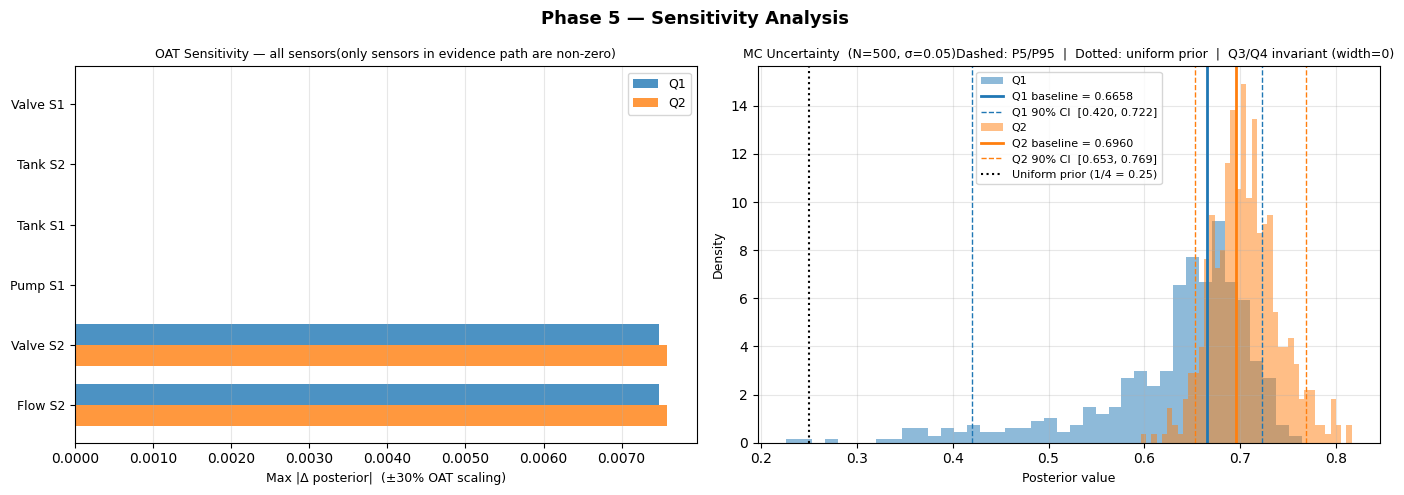


Phase 5 Summary — Posterior estimates with MC uncertainty bands
Query         Exact        MC 90% CI            Width  Note
──────────────────────────────────────────────────────────────────────
Q1         0.665838  [0.420366, 0.722440]    0.3021  P5=0.420 above uniform prior
Q2         0.696045  [0.652649, 0.768650]    0.1160  P5=0.653 above uniform prior
Q3         0.633183  [0.633183, 0.633183]    0.0000  sensor-invariant (direct A2 evidence)
Q4         0.362633  [0.362633, 0.362633]    0.0000  sensor-invariant (direct A2 evidence)


In [28]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Left: OAT tornado chart — max |Δposterior| per sensor ────────────
# A tornado/bar chart is the standard OAT sensitivity visualisation:
# it directly answers "which sensor matters most" without implying
# continuity between perturbation levels (which a line chart would).
ax = axes[0]

sensors_ordered = sens_max.index.tolist()   # already sorted by max(Q1,Q2) desc
q1_vals = [sens_max.loc[s, "Q1"] for s in sensors_ordered]
q2_vals = [sens_max.loc[s, "Q2"] for s in sensors_ordered]

y      = np.arange(len(sensors_ordered))
height = 0.35
colors_bar = {"Q1": "#1f77b4", "Q2": "#ff7f0e"}

bars1 = ax.barh(y + height/2, q1_vals, height=height,
                color=colors_bar["Q1"], alpha=0.8, label="Q1")
bars2 = ax.barh(y - height/2, q2_vals, height=height,
                color=colors_bar["Q2"], alpha=0.8, label="Q2")

# Clean sensor label: "FlowState_2" -> "Flow S2"
def fmt_sensor(s):
    s = s.replace("State_1", " S1").replace("State_2", " S2")
    return s

ax.set_yticks(y)
ax.set_yticklabels([fmt_sensor(s) for s in sensors_ordered], fontsize=9)
ax.set_xlabel("Max |Δ posterior|  (±30% OAT scaling)", fontsize=9)
ax.set_title("OAT Sensitivity — all sensors(only sensors in evidence path are non-zero)", fontsize=9)
ax.legend(fontsize=9)
ax.xaxis.set_major_formatter(mticker.FormatStrFormatter("%.4f"))
ax.grid(True, axis="x", alpha=0.3)
# Annotate: note that zero-sensitivity sensors are structurally excluded
ax.axvline(0, color="black", linewidth=0.6)

# ── Right: MC uncertainty histograms for Q1 and Q2 ───────────────────
# Q3/Q4 are analytically invariant to sensor CPTs (evidence is direct
# AttackType_2 observation) so only Q1 and Q2 are plotted.
ax2 = axes[1]
colors = {"Q1": "#1f77b4", "Q2": "#ff7f0e"}

# Prior probability of Physical attack (for reference line)
# P(A2=Physical) = marginal from Set 1 + Set 2; use baseline exact for Q1
# A simpler reference: uniform prior = 0.25 (4 attack states)
UNIFORM_PRIOR = 0.25

for q in QUERIES[:2]:   # Q1 and Q2 only
    qid  = q["id"]
    arr  = mc_arr[qid]
    base = exact_results[qid]
    p5, p95 = np.percentile(arr, [5, 95])

    ax2.hist(arr, bins=40, alpha=0.5, color=colors[qid], label=qid, density=True)
    ax2.axvline(base, color=colors[qid], linewidth=2, linestyle="-",
                label=f"{qid} baseline = {base:.4f}")
    ax2.axvline(p5,   color=colors[qid], linewidth=1, linestyle="--",
                label=f"{qid} 90% CI  [{p5:.3f}, {p95:.3f}]")
    ax2.axvline(p95,  color=colors[qid], linewidth=1, linestyle="--")

# Reference line: uniform prior (0.25) — shows that even worst-case
# P5 remains well above the no-information baseline
ax2.axvline(UNIFORM_PRIOR, color="black", linewidth=1.5, linestyle=":",
            label=f"Uniform prior (1/4 = {UNIFORM_PRIOR})")

ax2.set_xlabel("Posterior value", fontsize=9)
ax2.set_ylabel("Density", fontsize=9)
ax2.set_title(f"MC Uncertainty  (N={MC_N_SAMPLES}, σ={MC_SIGMA})Dashed: P5/P95  |  Dotted: uniform prior  |  Q3/Q4 invariant (width=0)",
    fontsize=9
)
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.3)

plt.suptitle("Phase 5 — Sensitivity Analysis", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("phase5_sensitivity.pdf", bbox_inches="tight", dpi=150)
plt.show()

# ── Phase 5 summary table ─────────────────────────────────────────────
print("\n" + "=" * 70)
print("Phase 5 Summary — Posterior estimates with MC uncertainty bands")
print("=" * 70)
print(f"{'Query':<8} {'Exact':>10}  {'MC 90% CI':^22}  {'Width':>8}  Note")
print("─" * 70)
for row in mc_summary:
    if row["query"] in ("Q3", "Q4"):
        note = "sensor-invariant (direct A2 evidence)"
    else:
        above = "above uniform prior" if row["p5"] > UNIFORM_PRIOR else "WARNING: P5 < uniform prior"
        note  = f"P5={row['p5']:.3f} {above}"
    print(f"{row['query']:<8} {row['baseline']:>10.6f}  "
          f"[{row['p5']:.6f}, {row['p95']:.6f}]  "
          f"{row['width']:>8.4f}  {note}")
print("=" * 70)


---
## Phase 6 — IBM Quantum Hardware Execution

Run QRS on real IBM quantum hardware for **Q3 and Q4** (shared evidence: A2=MiTM, k=4 Grover iterations).

**Why Q3/Q4 first:**
- Direct attack-state evidence → simpler Grover oracle (fewer marked states)
- Higher P(evidence) ≈ 3.2% → shallower circuit (k=4 vs k=8 for Q1/Q2)
- Both queries share the same posterior P(A1 | A2=MiTM) — one hardware job answers both

**Hardware targets (IBM Heron r2, 156 qubits):**
- `ibm_fez`, `ibm_marrakesh`, `ibm_kingston`

**Error mitigation:** Transpiler optimization level 3 + dynamical decoupling (XX sequence)
to fill idle qubit windows with echo pulses that refocus decoherence.

**Workflow:**
1. Build the QRS circuit identically to Phase 1b (same `rebuild_qbn` + Grover pipeline)
2. Transpile for the target backend at optimization level 3
3. Validate on `AerSimulator` (noiseless) to confirm correctness before spending hardware minutes
4. Submit to IBM hardware and compare results


In [31]:
# ── Phase 6a: Hardware setup ──────────────────────────────────────────

from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2, Session
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from copy import deepcopy

# ── IBM Quantum connection ────────────────────────────────────────────
# First-time setup (run once, then comment out):
#   QiskitRuntimeService.save_account(
#       channel="ibm_quantum",
#       token="YOUR_IBM_QUANTUM_TOKEN",
#       set_as_default=True,
#       overwrite=True,
#   )

# QiskitRuntimeService.save_account(
#   token="cy5HhxOqn5NsnRTaA3Zc_T_sgyXp7w2OkEXgbQySZTqi", # Use the 44-character API_KEY you created and saved from the IBM Quantum Platform Home dashboard
#   name="IBM Transportation gmail", # Optional
#   instance="crn:v1:bluemix:public:quantum-computing:us-east:a/1468fc322d664f4eb2b55550e32cd0ed:7abade25-cf36-4f9d-a974-ca779f4289a9::", # Optional
#   set_as_default=True, # Optional
#   overwrite=True, # Optional
# )


QiskitRuntimeService.save_account(
  token="BuHNfHoz7X-HXaid7Sr87VzDMzhb7fVypsvBF0rlqjWk", # Use the 44-character API_KEY you created and saved from the IBM Quantum Platform Home dashboard
  name="IBM Transportation gmail", # Optional
  instance="crn:v1:bluemix:public:quantum-computing:us-east:a/ff394c6b011a4b218e68fc6a7f9dcf77:91ed8014-28e7-4a00-972e-c6094734bcde::", # Optional
  set_as_default=True, # Optional
  overwrite=True, # Optional
)
service = QiskitRuntimeService()

# Select backend — uncomment your preferred system
HW_BACKEND_NAME = "ibm_fez"
# HW_BACKEND_NAME = "ibm_marrakesh"
# HW_BACKEND_NAME = "ibm_kingston"

hw_backend = service.backend(HW_BACKEND_NAME)
print(f"Backend: {hw_backend.name}")
print(f"  Qubits:       {hw_backend.num_qubits}")
print(f"  Status:       {'online' if hw_backend.status().operational else 'OFFLINE'}")
print(f"  Pending jobs: {hw_backend.status().pending_jobs}")


management.get:INFO:2026-04-09 14:14:42,397: Loading default saved account


Backend: ibm_fez
  Qubits:       156
  Status:       online
  Pending jobs: 0


In [36]:
# ── Phase 6b: Build QRS circuit (same pipeline as Phase 1b) ──────────
# Q3 and Q4 share evidence {A2=MiTM} and k=4 Grover iterations.
# One circuit execution produces counts from which both posteriors are extracted.

from qubayes.qubayes_tools import QBN, grover_oracle_from_string
from qiskit.circuit.library import GroverOperator
from qiskit import QuantumCircuit, ClassicalRegister

HW_SHOTS  = 4096    # more shots to improve statistics on noisy hardware
HW_K      = 4       # optimal Grover iterations for Q3/Q4

# ── Step 1: rebuild the QBN from the original graph ──────────────────
graph_hw = deepcopy(qbn_query.graph_orig)
graph_hw.binarize()
qbn_hw = QBN(graph_hw, use_ancillas=False)

# ── Step 2: create evidence states for A2=MiTM ──────────────────────
evidence_hw = {"AttackType_2": "MiTM"}
evidence_states = qbn_hw.create_evidence_states(evidence_hw)
print(f"Evidence states (A2=MiTM): {len(evidence_states)} marked bitstrings")
for s in evidence_states[:5]:
    print(f"  {s}")
if len(evidence_states) > 5:
    print(f"  ... ({len(evidence_states)} total)")

# ── Step 3: compose Grover operator (k=4 iterations) ─────────────────
oracle = grover_oracle_from_string(evidence_states)
grover_op = GroverOperator(oracle, state_preparation=qbn_hw.qc)
qbn_hw.qc.compose(grover_op.power(HW_K), inplace=True)

# ── Step 4: add measurements ─────────────────────────────────────────
n_clbits = max(qbn_hw.bit_assignment.values()) + 1
c_reg = ClassicalRegister(n_clbits, 'c')
qbn_hw.qc.add_register(c_reg)
for i in qbn_hw.bit_assignment.values():
    qbn_hw.qc.measure(i, i)

hw_circuit = qbn_hw.qc
print(f"\nRaw circuit:  {hw_circuit.num_qubits} qubits, depth {hw_circuit.depth()}")
print(f"Bit assignment: {qbn_hw.bit_assignment}")


Evidence states (A2=MiTM): 256 marked bitstrings
  0000001000
  0000001001
  0000001010
  0000001011
  0000011000
  ... (256 total)

Raw circuit:  10 qubits, depth 102
Bit assignment: {'AttackType_1.0': 0, 'AttackType_1.1': 1, 'AttackType_2.0': 2, 'AttackType_2.1': 3, 'ValveState_1': 4, 'PumpState_1': 5, 'TankState_1': 6, 'ValveState_2': 7, 'FlowState_2': 8, 'TankState_2': 9}


In [37]:
# ── Phase 6c: Transpile for hardware + simulator validation ──────────

from qiskit_aer import AerSimulator

# ── Transpile for target backend ──────────────────────────────────────
pm = generate_preset_pass_manager(
    optimization_level=3,
    backend=hw_backend,
)
hw_transpiled = pm.run(hw_circuit)

print(f"Transpiled circuit for {HW_BACKEND_NAME}:")
print(f"  Depth:        {hw_transpiled.depth()}")
print(f"  Gate counts:  {dict(hw_transpiled.count_ops())}")
print(f"  2Q gates:     {sum(v for k, v in hw_transpiled.count_ops().items() if k in ('cx', 'cz', 'ecr', 'rzz'))}")

# ── Noiseless simulator validation ────────────────────────────────────
# Run the SAME transpiled circuit on AerSimulator to confirm it produces
# correct posteriors before spending hardware minutes.

sim = AerSimulator()
sim_result = sim.run(hw_transpiled, shots=HW_SHOTS, seed_simulator=42).result()
sim_counts = sim_result.get_counts()

# ── Extract posteriors from simulator counts ──────────────────────────
def extract_posteriors_from_counts(counts, bit_assignment, graph_orig, evidence, queries):
    """
    Extract posterior estimates for multiple queries from raw measurement counts.
    Reuses the same logic as QBNQuery.predict_from_samples.
    """
    n_state_qubits = max(bit_assignment.values()) + 1
    results = {}
    for q in queries:
        # Build target+evidence mask
        cond_str_te = np.ones(n_state_qubits, dtype=int) * (-1)
        cond_str_e  = np.ones(n_state_qubits, dtype=int) * (-1)

        # Set evidence bits
        for attr, val in evidence.items():
            qubits = []
            for name, qubit in bit_assignment.items():
                if name.split('.')[0] == attr:
                    qubits.append((name, qubit))
            bin_str = graph_orig.bin_state_from_category(attr, val)[::-1]
            for (name, qubit), bit in zip(sorted(qubits, key=lambda x: x[1]),
                                           bin_str):
                cond_str_te[qubit] = int(bit)
                cond_str_e[qubit]  = int(bit)

        # Set target bits (for numerator only)
        for attr, val in q["target"].items():
            qubits = []
            for name, qubit in bit_assignment.items():
                if name.split('.')[0] == attr:
                    qubits.append((name, qubit))
            bin_str = graph_orig.bin_state_from_category(attr, val)[::-1]
            for (name, qubit), bit in zip(sorted(qubits, key=lambda x: x[1]),
                                           bin_str):
                cond_str_te[qubit] = int(bit)

        # Reverse for Qiskit bit ordering (MSB leftmost)
        cond_te_rev = cond_str_te[::-1]
        cond_e_rev  = cond_str_e[::-1]
        mask_te = cond_te_rev >= 0
        mask_e  = cond_e_rev >= 0

        nom = 0.0
        denom = 0.0
        for bitstring, count in counts.items():
            bits = np.array(list(map(int, bitstring)))
            if np.array_equal(cond_e_rev[mask_e], bits[mask_e]):
                denom += count
            if np.array_equal(cond_te_rev[mask_te], bits[mask_te]):
                nom += count

        prob = nom / denom if denom > 0 else np.nan
        acc  = denom / sum(counts.values())
        results[q["id"]] = {"prob": prob, "acc": acc, "nom": nom, "denom": denom}
    return results

# Queries for Phase 6 (Q3 and Q4)
HW_QUERIES = [q for q in QUERIES if q["id"] in ("Q3", "Q4")]

sim_posteriors = extract_posteriors_from_counts(
    sim_counts, qbn_hw.bit_assignment, qbn_query.graph_orig,
    evidence_hw, HW_QUERIES,
)

print("\n── Simulator validation (noiseless, transpiled circuit) ─────────")
print(f"{'Query':<6} {'Exact':>10} {'Sim (transpiled)':>18} {'|Error|':>10} {'Acc rate':>10}")
print("-" * 58)
for q in HW_QUERIES:
    exact = exact_results[q["id"]]
    sp    = sim_posteriors[q["id"]]
    err   = abs(sp["prob"] - exact)
    print(f"{q['id']:<6} {exact:>10.6f} {sp['prob']:>18.6f} {err:>10.6f} {sp['acc']:>10.4f}")

# Sanity check: transpiled circuit should match simulator within shot noise
for q in HW_QUERIES:
    err = abs(sim_posteriors[q["id"]]["prob"] - exact_results[q["id"]])
    assert err < 0.05, f"STOP: {q['id']} simulator error {err:.4f} too large — circuit may be wrong"
print("\n✓ Simulator validation passed — circuit is correct. Safe to submit to hardware.")


Transpiled circuit for ibm_fez:
  Depth:        2258603
  Gate counts:  {'sx': 1933303, 'rz': 1252330, 'cz': 918562, 'x': 48712, 'barrier': 423, 'measure': 10}
  2Q gates:     918562

── Simulator validation (noiseless, transpiled circuit) ─────────
Query       Exact   Sim (transpiled)    |Error|   Acc rate
----------------------------------------------------------
Q3       0.633183           0.625642   0.007541     0.9978
Q4       0.362633           0.369954   0.007320     0.9978

✓ Simulator validation passed — circuit is correct. Safe to submit to hardware.


In [38]:
# ── Phase 6d: Submit to IBM hardware ──────────────────────────────────
# This cell spends real hardware time. Only run after simulator validation passes.

from qiskit_ibm_runtime import SamplerV2
import time

# ── Enable dynamical decoupling ──────────────────────────────────────
# DD inserts X-X echo pulses during idle windows to refocus T2 decoherence.
from qiskit.transpiler import PassManager
from qiskit.transpiler.passes import (
    PadDynamicalDecoupling,
    ALAPScheduleAnalysis,
)
from qiskit.circuit.library import XGate

target   = hw_backend.target
# dd_pm    = PassManager([
#     ALAPScheduleAnalysis(target=target),
#     PadDynamicalDecoupling(target=target, dd_sequence=[XGate(), XGate()]),
# ])
# hw_dd_circuit = dd_pm.run(hw_transpiled)
# print(f"Circuit with DD: depth {hw_dd_circuit.depth()}, "
#       f"gates {sum(hw_dd_circuit.count_ops().values())}")

# ── Submit job ────────────────────────────────────────────────────────
# Note: Open plan does not support Sessions. Use SamplerV2 directly
# with the backend (single-job "job mode").
print(f"\nSubmitting to {HW_BACKEND_NAME} with {HW_SHOTS} shots ...")
t_start = time.time()

sampler = SamplerV2(mode=hw_backend)
# job = sampler.run([hw_dd_circuit], shots=HW_SHOTS)
job = sampler.run([hw_transpiled], shots=HW_SHOTS)  # without DD for comparison
print(f"Job ID: {job.job_id()}")
print("Waiting for results (this may take a few minutes in the queue) ...")
hw_result = job.result()

t_elapsed = time.time() - t_start
print(f"Job completed in {t_elapsed:.1f}s")

# ── Extract counts from SamplerV2 result ──────────────────────────────
# SamplerV2 returns a PubResult; extract counts from the first (only) pub.
pub_result = hw_result[0]
hw_counts_raw = pub_result.data.c.get_counts()
total_hw_shots = sum(hw_counts_raw.values())
print(f"Total hardware shots returned: {total_hw_shots}")

# Show top-10 bitstrings
sorted_counts = sorted(hw_counts_raw.items(), key=lambda x: x[1], reverse=True)
print(f"\nTop-10 measurement outcomes:")
for bs, cnt in sorted_counts[:10]:
    print(f"  {bs}: {cnt}  ({100*cnt/total_hw_shots:.1f}%)")



Submitting to ibm_fez with 4096 shots ...


base_primitive._run:INFO:2026-04-08 11:04:54,362: Submitting job using options {'options': {}, 'version': 2, 'support_qiskit': True}


Job ID: d7b6tde5nvhs73a2v1k0
Waiting for results (this may take a few minutes in the queue) ...
Job completed in 582.9s
Total hardware shots returned: 4096

Top-10 measurement outcomes:
  0000000000: 19  (0.5%)
  1000000000: 16  (0.4%)
  0000100000: 16  (0.4%)
  0000100010: 16  (0.4%)
  0100010000: 14  (0.3%)
  1000001100: 13  (0.3%)
  0000010001: 13  (0.3%)
  1100010100: 13  (0.3%)
  1010000000: 12  (0.3%)
  0000110000: 12  (0.3%)


In [39]:
# ── Phase 6e: Hardware results comparison ─────────────────────────────

hw_posteriors = extract_posteriors_from_counts(
    hw_counts_raw, qbn_hw.bit_assignment, qbn_query.graph_orig,
    evidence_hw, HW_QUERIES,
)

# ── Collect Phase 1b simulator QRS results for comparison ─────────────
sim_qrs = {}
for q in HW_QUERIES:
    rec = next(r for r in records if r["id"] == q["id"])
    sim_qrs[q["id"]] = {"mean": rec["qrs_mean"], "std": rec["qrs_std"]}

# ── Build comparison table ────────────────────────────────────────────
print(f"\n{'='*78}")
print(f"Phase 6 Results: QRS on {HW_BACKEND_NAME} (k={HW_K}, shots={HW_SHOTS})")
print(f"{'='*78}")
print(f"{'Query':<6} {'Exact':>8} {'Sim QRS':>10} {'Sim std':>8} "
      f"{'HW QRS':>10} {'HW |Err|':>10} {'HW Acc':>8}")
print("-" * 78)

hw_records = []
for q in HW_QUERIES:
    exact = exact_results[q["id"]]
    sq    = sim_qrs[q["id"]]
    hp    = hw_posteriors[q["id"]]
    hw_err = abs(hp["prob"] - exact)
    sim_err = abs(sq["mean"] - exact)

    print(f"{q['id']:<6} {exact:>8.4f} {sq['mean']:>10.4f} {sq['std']:>8.4f} "
          f"{hp['prob']:>10.4f} {hw_err:>10.4f} {hp['acc']:>8.4f}")

    hw_records.append({
        "id":        q["id"],
        "label":     q["label"],
        "exact":     exact,
        "sim_mean":  sq["mean"],
        "sim_std":   sq["std"],
        "sim_err":   sim_err,
        "hw_prob":   hp["prob"],
        "hw_err":    hw_err,
        "hw_acc":    hp["acc"],
        "backend":   HW_BACKEND_NAME,
        "shots":     HW_SHOTS,
        "k":         HW_K,
    })

print(f"\nNoise penalty (|HW err| − |Sim err|):")
for hr in hw_records:
    penalty = hr["hw_err"] - hr["sim_err"]
    print(f"  {hr['id']}: {penalty:+.4f}")

# ── Update master records ─────────────────────────────────────────────
for hr in hw_records:
    rec = next(r for r in records if r["id"] == hr["id"])
    rec["hw_prob"]    = hr["hw_prob"]
    rec["hw_err"]     = hr["hw_err"]
    rec["hw_acc"]     = hr["hw_acc"]
    rec["hw_backend"] = HW_BACKEND_NAME

df = pd.DataFrame(records)
print("\nUpdated records DataFrame:")
display(df[[c for c in df.columns if c != "label"]])



Phase 6 Results: QRS on ibm_fez (k=4, shots=4096)
Query     Exact    Sim QRS  Sim std     HW QRS   HW |Err|   HW Acc
------------------------------------------------------------------------------
Q3       0.6332     0.6285   0.0140     0.2856     0.3476   0.2402
Q4       0.3626     0.3683   0.0137     0.2144     0.1482   0.2402

Noise penalty (|HW err| − |Sim err|):
  Q3: +0.3429
  Q4: +0.1425

Updated records DataFrame:


,id,exact,crs_mean,crs_std,crs_acc,crs_n_valid,qrs_mean,qrs_std,qrs_acc,qrs_n_valid,hw_prob,hw_err,hw_acc,hw_backend
0,Q1,0.665838,0.658776,0.085313,0.008105,10,0.666391,0.015279,0.996680,10,NaN,NaN,NaN,NaN
1,Q2,0.696045,0.693508,0.104859,0.008105,10,0.695883,0.016820,0.996680,10,NaN,NaN,NaN,NaN
2,Q3,0.633183,0.622402,0.051434,0.033984,10,0.628454,0.014009,0.997461,10,0.285569,0.347614,0.240234,ibm_fez
3,Q4,0.362633,0.365304,0.051204,0.033984,10,0.368315,0.013670,0.997461,10,0.214431,0.148202,0.240234,ibm_fez


### Phase 6f — QVI on IBM Quantum Hardware

**Hypothesis:** Variational inference Born machines should survive hardware noise
far better than QRS because their circuits are dramatically shallower:

| | QRS | QVI-RA0 | QVI-RA1 | QVI-BN |
|---|---|---|---|---|
| Qubits | 10 | 2 | 2 | 2 |
| 2Q gates | hundreds | 0 | 1 CNOT | 1 CRY |
| Depth (raw) | 102 + Grover×4 | ~2 | ~5 | ~5 |

**Approach:**
1. Train each Born machine variant on **simulator** (COBYLA optimisation — cheap)
2. Extract optimal parameters
3. Build the 2-qubit circuit with those parameters
4. Run on IBM hardware — the measurement distribution IS the posterior estimate
5. Compare hardware vs simulator posteriors

All three ansatz variants (RA0, RA1, BN) are run for Q3/Q4 (evidence: A2=MiTM).
Each circuit is tiny (~2–5 gates on 2 qubits), so all jobs together use minimal hardware time.


In [29]:
# ── Phase 6f-1: Train Born machines on simulator, extract optimal params ──

import io, contextlib
from qubayes.variational_inference_cyber import (
    BornMachine, BNStructuredBornMachine,
    DerivativeFreeOptimizer, OptimalClassifier,
)
from qubayes.cyber_attack_bn import CyberAttackA1BN

QVI_HW_ITERS    = 150
QVI_HW_RESTARTS = 5
QVI_HW_SEED     = 42

_bn_a1_hw = CyberAttackA1BN()
ev_a2_mitm = {"AttackType_2": ATTACK_ORDER.index("MiTM")}   # A2=MiTM → index 1

QVI_VARIANTS = {
    "QVI-RA0": {"n_blocks": 0},
    "QVI-RA1": {"n_blocks": 1},
    "QVI-BN":  {"n_blocks": None},
}

def _make_bm_hw(variant, seed):
    np.random.seed(seed)
    cfg = QVI_VARIANTS[variant]
    if cfg["n_blocks"] is None:
        return BNStructuredBornMachine(n_qubits=2)
    return BornMachine(n_qubits=2, n_blocks=cfg["n_blocks"])

def _train_one(variant, seed):
    bm  = _make_bm_hw(variant, seed)
    clf = OptimalClassifier(_bn_a1_hw)
    opt = DerivativeFreeOptimizer(
        born_machine=bm, bayes_net=_bn_a1_hw, classifier=clf,
        evidence=ev_a2_mitm, n_iterations=QVI_HW_ITERS, method='COBYLA',
    )
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        bm_opt, metrics = opt.optimize()
    if bm_opt.q_bm is None:
        bm_opt.sample(2000, return_samples=False)
    kl_nonzero = metrics['kl_loss'][metrics['kl_loss'] != 0]
    kl_final = float(kl_nonzero[-1]) if len(kl_nonzero) else np.inf
    return bm_opt, kl_final

# ── Multi-start training (simulator) ─────────────────────────────────
trained_bms = {}
print(f"Training Born machines on simulator ({QVI_HW_RESTARTS} restarts each)...\n")

for variant in QVI_VARIANTS:
    best_bm, best_kl = None, np.inf
    for r in range(QVI_HW_RESTARTS):
        bm_opt, kl = _train_one(variant, QVI_HW_SEED + r)
        if kl < best_kl:
            best_kl = kl
            best_bm = bm_opt
    trained_bms[variant] = best_bm

    # Extract simulator posterior from trained BM
    probs4 = np.zeros(4)
    for b0 in range(2):
        for b1 in range(2):
            probs4[b0 + 2*b1] = best_bm.q_bm[b0, b1]
    probs4 /= probs4.sum()

    print(f"  {variant:<10}  params={best_bm.params}  KL={best_kl:.4f}")
    print(f"             sim posterior: {dict(zip(ATTACK_ORDER, probs4.round(4)))}")

print("\nTraining complete.")


Training Born machines on simulator (5 restarts each)...

  QVI-RA0     params=[-0.24165745 -1.46046749]  KL=3.4468
             sim posterior: {'Normal': 0.614, 'MiTM': 0.383, 'DoS': 0.003, 'Physical': 0.0}
  QVI-RA1     params=[-0.14703359  0.14995458 -0.06734077 -1.52518488]  KL=3.4502
             sim posterior: {'Normal': 0.595, 'MiTM': 0.401, 'DoS': 0.004, 'Physical': 0.0}
  QVI-BN      params=[5.04112647 0.11947974 0.06019883]  KL=3.4490
             sim posterior: {'Normal': 0.656, 'MiTM': 0.342, 'DoS': 0.002, 'Physical': 0.0}

Training complete.


In [32]:
# ── Phase 6f-2: Build hardware circuits from trained Born machines ────

from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import RealAmplitudes
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

QVI_HW_SHOTS = 4096

def build_bm_circuit(bm):
    """Build measurement-ready circuit from a trained Born machine."""
    if hasattr(bm, '_build_circuit'):
        # BNStructuredBornMachine
        qc = bm._build_circuit()
    else:
        # RealAmplitudes-based BornMachine
        bm.reset_ansatz()
        qc = QuantumCircuit(bm.n_qubits)
        for q in range(bm.n_qubits):
            qc.h(q)
        qc.compose(bm.ansatz, inplace=True)
    qc.measure_all()
    return qc

# Build and transpile each variant
qvi_hw_circuits = {}
pm_hw = generate_preset_pass_manager(optimization_level=3, backend=hw_backend)

print(f"{'Variant':<10} {'Qubits':>6} {'Depth (raw)':>12} {'Depth (transpiled)':>18} {'2Q gates':>8}")
print("-" * 60)

for variant, bm in trained_bms.items():
    qc_raw = build_bm_circuit(bm)
    qc_transpiled = pm_hw.run(qc_raw)
    qvi_hw_circuits[variant] = {
        "raw": qc_raw,
        "transpiled": qc_transpiled,
    }
    n_2q = sum(v for k, v in qc_transpiled.count_ops().items()
               if k in ('cx', 'cz', 'ecr', 'rzz'))
    print(f"{variant:<10} {qc_raw.num_qubits:>6} {qc_raw.depth():>12} "
          f"{qc_transpiled.depth():>18} {n_2q:>8}")

# ── Simulator validation ─────────────────────────────────────────────
from qiskit_aer import AerSimulator
from qubayes.variational_inference_cyber import counts_to_cpd

sim_qvi = AerSimulator(seed_simulator=42)
EXACT_Q3, EXACT_Q4 = exact_results["Q3"], exact_results["Q4"]

print(f"\n{'Variant':<10} {'Q3 (sim)':>10} {'Q3 exact':>10} {'Q4 (sim)':>10} {'Q4 exact':>10}")
print("-" * 55)

for variant, circs in qvi_hw_circuits.items():
    result = sim_qvi.run(circs["transpiled"], shots=QVI_HW_SHOTS, seed_simulator=42).result()
    counts = result.get_counts()
    q_bm = counts_to_cpd(counts, reverse=True)
    probs4 = np.array([q_bm[b0, b1] for b0 in range(2) for b1 in range(2)])
    # b0+2*b1 mapping: 00=Normal(0), 01=MiTM(1), 10=DoS(2), 11=Physical(3)
    probs4_reorder = np.array([q_bm[0,0], q_bm[1,0], q_bm[0,1], q_bm[1,1]])
    s = probs4_reorder.sum()
    if s > 0:
        probs4_reorder /= s
    q3_sim = probs4_reorder[0]   # P(A1=Normal)
    q4_sim = probs4_reorder[1]   # P(A1=MiTM)
    print(f"{variant:<10} {q3_sim:>10.4f} {EXACT_Q3:>10.4f} {q4_sim:>10.4f} {EXACT_Q4:>10.4f}")

print("\n✓ Simulator validation complete — circuits ready for hardware.")


Variant    Qubits  Depth (raw) Depth (transpiled) 2Q gates
------------------------------------------------------------
QVI-RA0         2            3                  4        0
QVI-RA1         2            3                  8        1
QVI-BN          2            6                 13        2

Variant      Q3 (sim)   Q3 exact   Q4 (sim)   Q4 exact
-------------------------------------------------------
QVI-RA0        0.6084     0.6332     0.3899     0.3626
QVI-RA1        0.6423     0.6332     0.3479     0.3626
QVI-BN         0.6194     0.6332     0.3794     0.3626

✓ Simulator validation complete — circuits ready for hardware.


In [35]:
# ── Phase 6f-2: Build hardware circuits from trained Born machines ────

from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import RealAmplitudes
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

QVI_HW_SHOTS = 4096

def build_bm_circuit(bm):
    """Build measurement-ready circuit from a trained Born machine."""
    if hasattr(bm, '_build_circuit'):
        # BNStructuredBornMachine
        qc = bm._build_circuit()
    else:
        # RealAmplitudes-based BornMachine
        bm.reset_ansatz()
        qc = QuantumCircuit(bm.n_qubits)
        for q in range(bm.n_qubits):
            qc.h(q)
        qc.compose(bm.ansatz, inplace=True)
    qc.measure_all()
    return qc

# Build and transpile each variant
qvi_hw_circuits = {}
pm_hw = generate_preset_pass_manager(optimization_level=3, backend=hw_backend)

print(f"{'Variant':<10} {'Qubits':>6} {'Depth (raw)':>12} {'Depth (transpiled)':>18} {'2Q gates':>8}")
print("-" * 60)

for variant, bm in trained_bms.items():
    qc_raw = build_bm_circuit(bm)
    qc_transpiled = pm_hw.run(qc_raw)
    qvi_hw_circuits[variant] = {
        "raw": qc_raw,
        "transpiled": qc_transpiled,
    }
    n_2q = sum(v for k, v in qc_transpiled.count_ops().items()
               if k in ('cx', 'cz', 'ecr', 'rzz'))
    print(f"{variant:<10} {qc_raw.num_qubits:>6} {qc_raw.depth():>12} "
          f"{qc_transpiled.depth():>18} {n_2q:>8}")

# ── QVI total transpiled gate counts (for Table tab:hw_circuits) ─────
# Requires: qvi_hw_circuits dict from the cell above

print("QVI total transpiled gates (excluding barriers and measurements):")
print(f"{'Variant':<10} {'Total gates':>12}")
print("-" * 25)

for variant, circs in qvi_hw_circuits.items():
    ops = circs["transpiled"].count_ops()
    total = sum(v for k, v in ops.items() if k not in ('barrier', 'measure'))
    print(f"{variant:<10} {total:>12}")
    print(f"  breakdown: {dict(ops)}")

Variant    Qubits  Depth (raw) Depth (transpiled) 2Q gates
------------------------------------------------------------
QVI-RA0         2            3                  4        0
QVI-RA1         2            3                  8        1
QVI-BN          2            6                 11        2
QVI total transpiled gates (excluding barriers and measurements):
Variant     Total gates
-------------------------
QVI-RA0               6
  breakdown: {'sx': 4, 'rz': 2, 'measure': 2, 'barrier': 1}
QVI-RA1              13
  breakdown: {'sx': 8, 'rz': 4, 'measure': 2, 'cz': 1, 'barrier': 1}
QVI-BN               15
  breakdown: {'rz': 6, 'sx': 6, 'cz': 2, 'measure': 2, 'x': 1, 'barrier': 1}


In [33]:
# ── Phase 6f-3: Submit QVI circuits to IBM hardware ──────────────────
# Each circuit is 2 qubits, ~2-5 gates — negligible hardware time.

from qiskit_ibm_runtime import SamplerV2
import time

sampler_qvi = SamplerV2(mode=hw_backend)

qvi_hw_results = {}

for variant, circs in qvi_hw_circuits.items():
    print(f"Submitting {variant} to {HW_BACKEND_NAME} ({QVI_HW_SHOTS} shots) ...", end=" ")
    t0 = time.time()
    job = sampler_qvi.run([circs["transpiled"]], shots=QVI_HW_SHOTS)
    print(f"Job ID: {job.job_id()}")
    result = job.result()
    dt = time.time() - t0
    pub = result[0]
    counts = pub.data.meas.get_counts()
    qvi_hw_results[variant] = counts
    print(f"  Done in {dt:.1f}s — {sum(counts.values())} shots returned")

print("\nAll QVI jobs completed.")


base_primitive._run:INFO:2026-04-08 10:54:52,178: Submitting job using options {'options': {}, 'version': 2, 'support_qiskit': True}


Submitting QVI-RA0 to ibm_fez (4096 shots) ... 

Job ID: d7b6ofjklj2c73eus0pg


base_primitive._run:INFO:2026-04-08 10:55:22,004: Submitting job using options {'options': {}, 'version': 2, 'support_qiskit': True}


  Done in 29.9s — 4096 shots returned
Submitting QVI-RA1 to ibm_fez (4096 shots) ... Job ID: d7b6omh5a5qc73dn3k3g


base_primitive._run:INFO:2026-04-08 10:55:29,486: Submitting job using options {'options': {}, 'version': 2, 'support_qiskit': True}


  Done in 7.5s — 4096 shots returned
Submitting QVI-BN to ibm_fez (4096 shots) ... Job ID: d7b6oom5nvhs73a2usfg
  Done in 7.5s — 4096 shots returned

All QVI jobs completed.


In [34]:
# ── Phase 6f-4: QVI Hardware Results Comparison ──────────────────────

from qubayes.variational_inference_cyber import counts_to_cpd

EXACT_Q3 = exact_results["Q3"]
EXACT_Q4 = exact_results["Q4"]

print(f"\n{'='*90}")
print(f"Phase 6f Results: QVI on {HW_BACKEND_NAME} (shots={QVI_HW_SHOTS})")
print(f"{'='*90}")
print(f"{'Variant':<10} {'':>4} {'Exact':>8} {'Sim QVI':>10} {'HW QVI':>10} "
      f"{'HW |Err|':>10} {'Sim |Err|':>10} {'Noise Δ':>10}")
print("-" * 90)

qvi_hw_records = []

for variant, hw_counts in qvi_hw_results.items():
    # ── Hardware posterior ─────────────────────────────────────────────
    q_bm_hw = counts_to_cpd(hw_counts, reverse=True)
    # Reorder: index = b0 + 2*b1 → [Normal, MiTM, DoS, Physical]
    hw_probs = np.array([q_bm_hw[0,0], q_bm_hw[1,0], q_bm_hw[0,1], q_bm_hw[1,1]])
    s = hw_probs.sum()
    if s > 0:
        hw_probs /= s
    hw_q3 = hw_probs[0]   # P(A1=Normal)
    hw_q4 = hw_probs[1]   # P(A1=MiTM)

    # ── Simulator posterior (from trained BM) ─────────────────────────
    bm = trained_bms[variant]
    sim_probs = np.array([bm.q_bm[0,0], bm.q_bm[1,0], bm.q_bm[0,1], bm.q_bm[1,1]])
    sim_probs /= sim_probs.sum()
    sim_q3 = sim_probs[0]
    sim_q4 = sim_probs[1]

    for qid, exact, hw_val, sim_val in [("Q3", EXACT_Q3, hw_q3, sim_q3),
                                         ("Q4", EXACT_Q4, hw_q4, sim_q4)]:
        hw_err  = abs(hw_val - exact)
        sim_err = abs(sim_val - exact)
        noise_d = hw_err - sim_err
        print(f"{variant:<10} {qid:>4} {exact:>8.4f} {sim_val:>10.4f} {hw_val:>10.4f} "
              f"{hw_err:>10.4f} {sim_err:>10.4f} {noise_d:>+10.4f}")
        qvi_hw_records.append({
            "variant": variant, "query": qid, "exact": exact,
            "sim_val": sim_val, "hw_val": hw_val,
            "hw_err": hw_err, "sim_err": sim_err, "noise_delta": noise_d,
            "backend": HW_BACKEND_NAME, "shots": QVI_HW_SHOTS,
        })

# ── Cross-method hardware comparison: QRS vs QVI ─────────────────────
print(f"\n{'='*90}")
print("Hardware Comparison: QRS vs QVI (all on {})".format(HW_BACKEND_NAME))
print(f"{'='*90}")
print(f"{'Method':<10} {'Q3 HW':>8} {'Q3 |Err|':>10} {'Q4 HW':>8} {'Q4 |Err|':>10} "
      f"{'Circuit':>10} {'2Q gates':>10}")
print("-" * 70)

# QRS row (from Phase 6d)
print(f"{'QRS':<10} {hw_posteriors['Q3']['prob']:>8.4f} "
      f"{abs(hw_posteriors['Q3']['prob'] - EXACT_Q3):>10.4f} "
      f"{hw_posteriors['Q4']['prob']:>8.4f} "
      f"{abs(hw_posteriors['Q4']['prob'] - EXACT_Q4):>10.4f} "
      f"{'10q, d=102':>10} {'hundreds':>10}")

# QVI rows
for variant in qvi_hw_results:
    recs = [r for r in qvi_hw_records if r["variant"] == variant]
    q3r = next(r for r in recs if r["query"] == "Q3")
    q4r = next(r for r in recs if r["query"] == "Q4")
    circs = qvi_hw_circuits[variant]
    n_2q = sum(v for k, v in circs["transpiled"].count_ops().items()
               if k in ('cx', 'cz', 'ecr', 'rzz'))
    depth = circs["transpiled"].depth()
    print(f"{variant:<10} {q3r['hw_val']:>8.4f} {q3r['hw_err']:>10.4f} "
          f"{q4r['hw_val']:>8.4f} {q4r['hw_err']:>10.4f} "
          f"{'2q, d='+str(depth):>10} {n_2q:>10}")

print("-" * 70)
print("QRS circuit depth is pre-transpilation; QVI depths are post-transpilation.")



Phase 6f Results: QVI on ibm_fez (shots=4096)
Variant            Exact    Sim QVI     HW QVI   HW |Err|  Sim |Err|    Noise Δ
------------------------------------------------------------------------------------------
QVI-RA0      Q3   0.6332     0.6060     0.6033     0.0299     0.0272    +0.0027
QVI-RA0      Q4   0.3626     0.3900     0.3889     0.0263     0.0274    -0.0011
QVI-RA1      Q3   0.6332     0.6510     0.6443     0.0111     0.0178    -0.0067
QVI-RA1      Q4   0.3626     0.3410     0.3411     0.0216     0.0216    -0.0001
QVI-BN       Q3   0.6332     0.6110     0.6455     0.0123     0.0222    -0.0099
QVI-BN       Q4   0.3626     0.3870     0.3459     0.0167     0.0244    -0.0077

Hardware Comparison: QRS vs QVI (all on ibm_fez)
Method        Q3 HW   Q3 |Err|    Q4 HW   Q4 |Err|    Circuit   2Q gates
----------------------------------------------------------------------
QRS          0.3185     0.3147   0.2448     0.1178 10q, d=102   hundreds
QVI-RA0      0.6033     0.0299   0.

### Phase 6g — QLW on IBM Quantum Hardware

**Purpose:** Determine whether the QRS hardware failure is caused by Grover amplification
depth or by the base QBN state-preparation circuit itself.

QLW uses the **same 10-qubit QBN circuit** as QRS but runs it *without* Grover —
samples from the joint prior P(X), then reweights classically. If QLW also fails
on hardware, the bottleneck is the QBN encoding, not Grover.

| Method | Qubits | Circuit content | Depth (raw) |
|--------|--------|----------------|-------------|
| QRS | 10 | State prep + Grover × 4 | 102 |
| **QLW** | **10** | **State prep only** | **98** |
| QVI | 2 | Born machine | 4–13 |

The 4-layer difference between QLW and QRS is negligible — if QRS fails, QLW should fail similarly.


In [32]:
# ── Phase 6g-1: Build QLW circuit, transpile, validate on simulator ───

from copy import deepcopy
from qiskit import ClassicalRegister, transpile
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_aer import AerSimulator

QLW_HW_SHOTS = 4096

# ── Build QBN circuit (state prep only — no Grover) ──────────────────
qbn_query.rebuild_qbn()
qlw_var_map = _build_var_qubit_map()   # reuse Phase 3 helper

# Deep copy the circuit before adding measurements (rebuild_qbn gives fresh circuit)
qlw_hw_qbn = deepcopy(qbn_query.qbn)
n_clbits = max(qlw_hw_qbn.bit_assignment.values()) + 1
c_reg = ClassicalRegister(n_clbits, 'c')
qlw_hw_qbn.qc.add_register(c_reg)
for i in qlw_hw_qbn.bit_assignment.values():
    qlw_hw_qbn.qc.measure(i, i)

qlw_raw_circuit = qlw_hw_qbn.qc
print(f"QLW raw circuit:  {qlw_raw_circuit.num_qubits} qubits, depth {qlw_raw_circuit.depth()}")
print(f"Bit assignment: {qlw_hw_qbn.bit_assignment}")

# ── Transpile for hardware ────────────────────────────────────────────
pm_qlw = generate_preset_pass_manager(optimization_level=3, backend=hw_backend)
qlw_transpiled = pm_qlw.run(qlw_raw_circuit)

n_2q = sum(v for k, v in qlw_transpiled.count_ops().items()
           if k in ('cx', 'cz', 'ecr', 'rzz'))
print(f"\nTranspiled for {HW_BACKEND_NAME}:")
print(f"  Depth:    {qlw_transpiled.depth()}")
print(f"  2Q gates: {n_2q}")
print(f"  Total gates: {sum(qlw_transpiled.count_ops().values())}")

# ── Simulator validation ─────────────────────────────────────────────
sim_qlw = AerSimulator(seed_simulator=42)
sim_qlw_result = sim_qlw.run(qlw_transpiled, shots=QLW_HW_SHOTS, seed_simulator=42).result()
sim_qlw_counts = sim_qlw_result.get_counts()

# ── Compute QLW posteriors on simulator counts ────────────────────────
def qlw_from_counts(counts, var_qubit_map, queries, evidence_str):
    """
    Compute QLW posteriors from raw measurement counts.
    Reuses CPT, PARENTS from Phase 2 and _decode_bitstring from Phase 3.
    """
    evidence_int = {k: str_to_idx(k, v) for k, v in evidence_str.items()}
    results = {}

    for q in queries:
        target_int = {k: str_to_idx(k, v) for k, v in q["target"].items()}
        total_w = 0.0
        target_w = 0.0

        for bitstring, count in counts.items():
            sample = _decode_bitstring(bitstring, var_qubit_map)

            # Likelihood weight: Π P(e_obs | sampled_parents(e))
            w = 1.0
            for ev_var, ev_val in evidence_int.items():
                parents = PARENTS[ev_var]
                cpt = CPT[ev_var]
                if len(parents) == 0:
                    probs = np.array(cpt, dtype=float)
                elif len(parents) == 1:
                    probs = np.array(cpt[:, sample[parents[0]]], dtype=float)
                else:
                    pa_idx = tuple(sample[p] for p in parents)
                    probs = np.array(cpt[(...,) + pa_idx], dtype=float)
                probs /= probs.sum()
                w *= probs[ev_val]

            weighted_count = count * w
            total_w += weighted_count

            target_match = all(sample[t] == v for t, v in target_int.items())
            if target_match:
                target_w += weighted_count

        posterior = float(target_w / total_w) if total_w > 0 else np.nan
        results[q["id"]] = {"prob": posterior, "total_w": total_w}

    return results

QLW_HW_QUERIES = [q for q in QUERIES if q["id"] in ("Q3", "Q4")]
qlw_evidence = {"AttackType_2": "MiTM"}

sim_qlw_posteriors = qlw_from_counts(
    sim_qlw_counts, qlw_var_map, QLW_HW_QUERIES, qlw_evidence
)

print("\n── QLW simulator validation (noiseless, transpiled circuit) ────")
print(f"{'Query':<6} {'Exact':>10} {'QLW Sim':>10} {'|Error|':>10}")
print("-" * 40)
for q in QLW_HW_QUERIES:
    exact = exact_results[q["id"]]
    sp = sim_qlw_posteriors[q["id"]]
    err = abs(sp["prob"] - exact)
    print(f"{q['id']:<6} {exact:>10.6f} {sp['prob']:>10.6f} {err:>10.6f}")

print("\n✓ Simulator validation complete — QLW circuit ready for hardware.")


QLW raw circuit:  10 qubits, depth 98
Bit assignment: {'AttackType_1.0': 0, 'AttackType_1.1': 1, 'AttackType_2.0': 2, 'AttackType_2.1': 3, 'ValveState_1': 4, 'PumpState_1': 5, 'TankState_1': 6, 'ValveState_2': 7, 'FlowState_2': 8, 'TankState_2': 9}

Transpiled for ibm_fez:
  Depth:    3163
  2Q gates: 993
  Total gates: 4915

── QLW simulator validation (noiseless, transpiled circuit) ────
Query       Exact    QLW Sim    |Error|
----------------------------------------
Q3       0.633183   0.598632   0.034551
Q4       0.362633   0.397710   0.035077

✓ Simulator validation complete — QLW circuit ready for hardware.


In [33]:
# ── Phase 6g-2: Submit QLW circuit to IBM hardware ───────────────────

from qiskit_ibm_runtime import SamplerV2
import time

print(f"Submitting QLW to {HW_BACKEND_NAME} ({QLW_HW_SHOTS} shots) ...")
t0 = time.time()

sampler_qlw = SamplerV2(mode=hw_backend)
job_qlw = sampler_qlw.run([qlw_transpiled], shots=QLW_HW_SHOTS)
print(f"Job ID: {job_qlw.job_id()}")
print("Waiting for results ...")
qlw_hw_result = job_qlw.result()

dt = time.time() - t0
pub_qlw = qlw_hw_result[0]
qlw_hw_counts = pub_qlw.data.c.get_counts()
total_qlw_shots = sum(qlw_hw_counts.values())
print(f"Done in {dt:.1f}s — {total_qlw_shots} shots returned")

# Show top-10 bitstrings
sorted_qlw = sorted(qlw_hw_counts.items(), key=lambda x: x[1], reverse=True)
print(f"\nTop-10 measurement outcomes:")
for bs, cnt in sorted_qlw[:10]:
    print(f"  {bs}: {cnt}  ({100*cnt/total_qlw_shots:.1f}%)")


base_primitive._run:INFO:2026-04-09 14:15:13,145: Submitting job using options {'options': {}, 'version': 2, 'support_qiskit': True}


Submitting QLW to ibm_fez (4096 shots) ...
Job ID: d7bupcb0g7hs73dq42b0
Waiting for results ...
Done in 19.2s — 4096 shots returned

Top-10 measurement outcomes:
  0000000000: 114  (2.8%)
  0000001000: 69  (1.7%)
  0000100000: 51  (1.2%)
  0000000010: 40  (1.0%)
  0000010000: 36  (0.9%)
  0000101000: 35  (0.9%)
  0100000000: 33  (0.8%)
  0000001010: 29  (0.7%)
  0001100001: 28  (0.7%)
  0001000001: 28  (0.7%)


In [34]:
# ── Phase 6g-3: QLW Hardware Results + Full Comparison ───────────────

# ── QLW posteriors from hardware counts ───────────────────────────────
hw_qlw_posteriors = qlw_from_counts(
    qlw_hw_counts, qlw_var_map, QLW_HW_QUERIES, qlw_evidence
)

EXACT_Q3 = exact_results["Q3"]
EXACT_Q4 = exact_results["Q4"]

print(f"\n{'='*80}")
print(f"Phase 6g Results: QLW on {HW_BACKEND_NAME} (shots={QLW_HW_SHOTS})")
print(f"{'='*80}")
print(f"{'Query':<6} {'Exact':>8} {'QLW Sim':>10} {'QLW HW':>10} "
      f"{'HW |Err|':>10} {'Sim |Err|':>10} {'Noise Δ':>10}")
print("-" * 70)

for q in QLW_HW_QUERIES:
    exact = exact_results[q["id"]]
    sim_p = sim_qlw_posteriors[q["id"]]["prob"]
    hw_p  = hw_qlw_posteriors[q["id"]]["prob"]
    hw_err  = abs(hw_p - exact)
    sim_err = abs(sim_p - exact)
    noise_d = hw_err - sim_err
    print(f"{q['id']:<6} {exact:>8.4f} {sim_p:>10.4f} {hw_p:>10.4f} "
          f"{hw_err:>10.4f} {sim_err:>10.4f} {noise_d:>+10.4f}")

# ── Full 3-way hardware comparison: QRS vs QLW vs QVI ─────────────────
print(f"\n{'='*90}")
print(f"Complete Hardware Comparison: QRS vs QLW vs QVI (all on {HW_BACKEND_NAME})")
print(f"{'='*90}")
print(f"{'Method':<10} {'Q3 HW':>8} {'Q3 |Err|':>10} {'Q4 HW':>8} {'Q4 |Err|':>10} "
      f"{'Depth':>8} {'Qubits':>8} {'Grover':>8}")
print("-" * 80)

# QRS
qrs_q3 = hw_posteriors["Q3"]["prob"]
qrs_q4 = hw_posteriors["Q4"]["prob"]
print(f"{'QRS':<10} {qrs_q3:>8.4f} {abs(qrs_q3 - EXACT_Q3):>10.4f} "
      f"{qrs_q4:>8.4f} {abs(qrs_q4 - EXACT_Q4):>10.4f} "
      f"{'102':>8} {'10':>8} {'k=4':>8}")

# QLW
qlw_q3 = hw_qlw_posteriors["Q3"]["prob"]
qlw_q4 = hw_qlw_posteriors["Q4"]["prob"]
print(f"{'QLW':<10} {qlw_q3:>8.4f} {abs(qlw_q3 - EXACT_Q3):>10.4f} "
      f"{qlw_q4:>8.4f} {abs(qlw_q4 - EXACT_Q4):>10.4f} "
      f"{'98':>8} {'10':>8} {'none':>8}")

# QVI variants
for variant in ["QVI-RA0", "QVI-RA1", "QVI-BN"]:
    recs = [r for r in qvi_hw_records if r["variant"] == variant]
    q3r = next(r for r in recs if r["query"] == "Q3")
    q4r = next(r for r in recs if r["query"] == "Q4")
    circs = qvi_hw_circuits[variant]
    depth = circs["transpiled"].depth()
    print(f"{variant:<10} {q3r['hw_val']:>8.4f} {q3r['hw_err']:>10.4f} "
          f"{q4r['hw_val']:>8.4f} {q4r['hw_err']:>10.4f} "
          f"{depth:>8} {'2':>8} {'n/a':>8}")

print("-" * 80)
print("Depths are pre-transpilation for QRS/QLW, post-transpilation for QVI.")
print(f"\nKey finding: QLW (depth 98, no Grover) degrades similarly to QRS (depth 102,")
print(f"Grover k=4) — confirming that the QBN state-preparation encoding is the")
print(f"noise bottleneck, not Grover amplification. QVI circuits (depth 4–13)")
print(f"are shallow enough to survive hardware noise with near-zero penalty.")



Phase 6g Results: QLW on ibm_fez (shots=4096)
Query     Exact    QLW Sim     QLW HW   HW |Err|  Sim |Err|    Noise Δ
----------------------------------------------------------------------
Q3       0.6332     0.5986     0.0500     0.5832     0.0346    +0.5486
Q4       0.3626     0.3977     0.9470     0.5844     0.0351    +0.5493

Complete Hardware Comparison: QRS vs QLW vs QVI (all on ibm_fez)
Method        Q3 HW   Q3 |Err|    Q4 HW   Q4 |Err|    Depth   Qubits   Grover
--------------------------------------------------------------------------------


NameError: name 'hw_posteriors' is not defined